# [설명가능한인공지능] 아파트 가격 예측 및 XAI 분석 과제

## AI·빅데이터학과 20231456 유지혜

### 1. 데이터 로드 및 전처리

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

# 데이터 로드
file_path = '/home/yu_jh/jihye/ji/jihye/s_project/data/Apart Deal.csv'
df = pd.read_csv(file_path)

# 데이터 크기 확인 및 일부 미리보기
print(df.shape)
df.head()

(5002839, 9)


,지역코드,법정동,거래일,아파트,지번,전용면적,층,건축년도,거래금액
0,31110.0,학성동,5/30/2020 0:00,남운학성타운,379,135.5800,8,1991.0,26700
1,31110.0,남외동,1/3/2020 0:00,남외푸르지오1차,506-1,101.6000,2,2006.0,35500
2,31110.0,남외동,1/3/2020 0:00,에일린의뜰,500,84.9920,11,2007.0,36500
3,31110.0,남외동,1/3/2020 0:00,남외푸르지오1차,506-1,118.7060,8,2006.0,43000
4,31110.0,남외동,1/4/2020 0:00,남외푸르지오2차,501-1,84.9636,7,2007.0,38700


In [ ]:
# <거래일 전처리>
# 문자열로 통일
s = df['거래일'].astype(str)

# 포맷 1: YYYY-MM-DD 형식 (시간 포함)
mask1 = s.str.contains(r'^\d{4}-\d{2}-\d{2}')
df.loc[mask1, '거래일_정제'] = pd.to_datetime(s[mask1], errors='coerce')

# 포맷 2: M/D/YYYY 또는 MM/DD/YYYY 형식
mask2 = s.str.contains(r'^\d{1,2}/\d{1,2}/\d{4}')
df.loc[mask2, '거래일_정제'] = pd.to_datetime(s[mask2], errors='coerce')

df['거래일_정제'] = pd.to_datetime(df['거래일_정제'], errors='coerce')

df['거래일_정제'] = df['거래일_정제'].dt.strftime('%Y-%m-%d')

# 거래일을 정제된 값으로 덮어쓰기
df['거래일'] = df['거래일_정제']

# 정제 열 제거
df.drop(columns=['거래일_정제'], inplace=True)

# <거래금액 전처리>
# 거래금액이 문자열일 때만 쉼표 제거 후 float 변환
df['거래금액'] = df['거래금액'].apply(lambda x: float(str(x).replace(',', '')) if pd.notnull(x) else np.nan)

# 억 단위 컬럼 생성
df['거래금액_억원'] = df['거래금액'] / 10000

# 거래일을 정제된 값으로 덮어쓰기
df['거래금액'] = df['거래금액_억원']

# 정제 열 제거
df.drop(columns=['거래금액_억원'], inplace=True)

# <건축연도 전처리>
df['건축년도'] = pd.to_numeric(df['건축년도'], errors='coerce').astype('Int64')

# <지역 전처리>
df['지역코드'] = df['지역코드'].astype('int')

# 법정동 코드 데이터 로드
code_df = pd.read_csv('/home/yu_jh/jihye/ji/jihye/s_project/data/국토교통부_전국 법정동_20250415.csv', dtype={'법정동코드': str})

# 시군구 단위 코드 추출 (상위 5자리: 시도 2자리 + 시군구 3자리)
code_df['지역코드'] = code_df['법정동코드'].str.slice(0, 5)

# 시군구 단위로 중복 제거
region_df = code_df[['지역코드', '시도명', '시군구명']].drop_duplicates()

# 원본 데이터의 지역코드 컬럼을 정수형으로 변환
df['지역코드'] = df['지역코드'].astype(str).str.slice(0, 5)

# 매핑 수행
df = df.merge(region_df, on='지역코드', how='left')

# 중복 컬럼 제거
df = df.drop(columns=['시도명_x', '시군구명_x'], errors='ignore')
df = df.drop(columns=['시도명_y', '시군구명_y'], errors='ignore')

df.head()

,지역코드,법정동,거래일,아파트,지번,전용면적,층,건축년도,거래금액,시도명,시군구명
0,31110,학성동,2020-05-30,남운학성타운,379,135.5800,8,1991,2.67,울산광역시,중구
1,31110,남외동,2020-01-03,남외푸르지오1차,506-1,101.6000,2,2006,3.55,울산광역시,중구
2,31110,남외동,2020-01-03,에일린의뜰,500,84.9920,11,2007,3.65,울산광역시,중구
3,31110,남외동,2020-01-03,남외푸르지오1차,506-1,118.7060,8,2006,4.30,울산광역시,중구
4,31110,남외동,2020-01-04,남외푸르지오2차,501-1,84.9636,7,2007,3.87,울산광역시,중구


### 2. 탐색적 데이터 분석 (EDA)

거래금액, 전용면적, 건축년도 분포

In [3]:
# 거래금액
min_price = df['거래금액'].min()
max_price = df['거래금액'].max()
print(f"거래금액 (억원 기준): {min_price}억 ~ {max_price}억")

# 전용면적
min_area = df['전용면적'].min()
max_area = df['전용면적'].max()
print(f"전용면적 범위: {min_area:.2f} ㎡ ~ {max_area:.2f} ㎡")

# 건축연도 최솟값 확인
min_year = df['건축년도'].min()
print(f"가장 오래된 건축연도: {int(min_year)}년")

거래금액 (억원 기준): 0.01억 ~ 145.0억
전용면적 범위: 9.26 ㎡ ~ 424.32 ㎡
가장 오래된 건축연도: 1961년


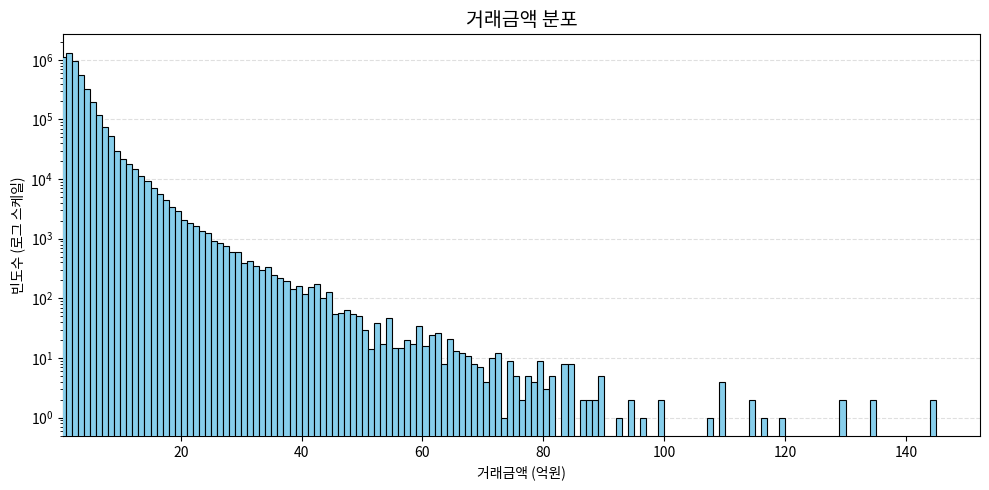

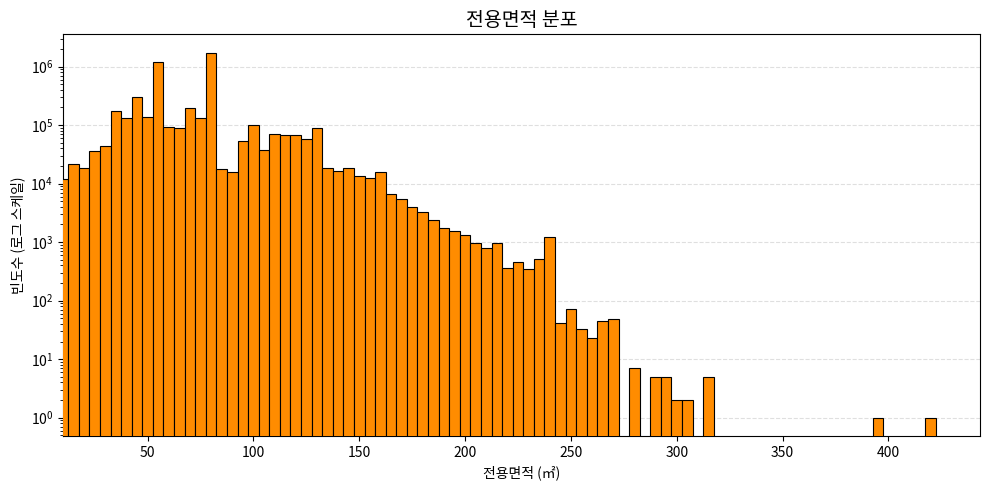

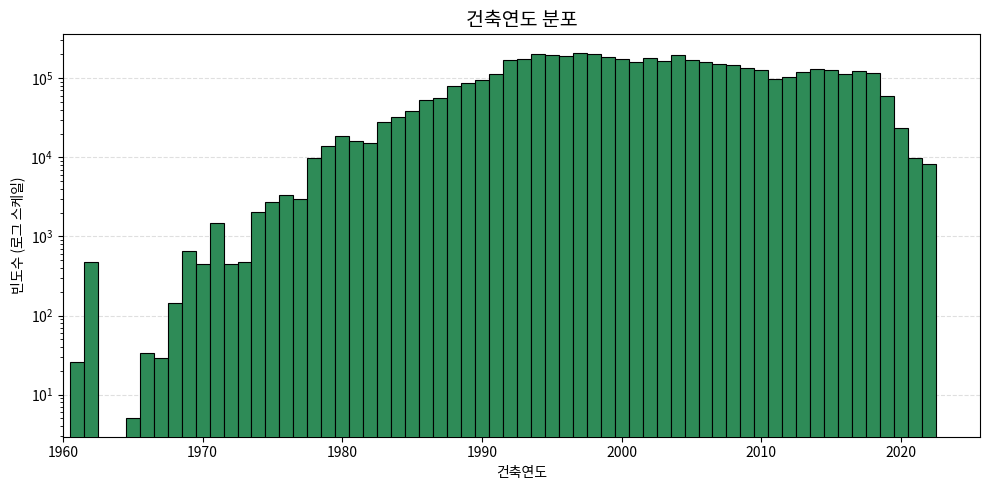

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import platform

plt.rc('font', family='Noto Sans CJK JP')
plt.rcParams['axes.unicode_minus'] = False

# 거래금액 정제 (문자형 → 숫자형)
if df['거래금액'].dtype == 'object':
    df['거래금액'] = df['거래금액'].str.replace(',', '').astype(float)

# 건축년도 → 건축연도로 변수명 변경
df.rename(columns={'건축년도': '건축연도'}, inplace=True)

# 히스토그램 그리기 함수
def plot_histogram_logy(data, column, title, xlabel, color='steelblue', bin_width=None, min_override=None):
    plt.figure(figsize=(10, 5))

    values = data[column].dropna()

    if bin_width:
        min_val = min_override if min_override is not None else np.floor(values.min())
        max_val = np.ceil(values.max())
        bins = np.arange(min_val, max_val + bin_width, bin_width)
    else:
        bins = 40

    ax = plt.gca()
    ax.hist(values, bins=bins, color=color,
            edgecolor='black', linewidth=0.8, align='left', zorder=3)

    ax.set_yscale('log')
    ax.set_title(title, fontsize=14)
    ax.set_xlabel(xlabel)
    ax.set_ylabel('빈도수 (로그 스케일)')
    ax.set_xlim(left=bins[0])
    ax.grid(axis='y', linestyle='--', alpha=0.4, zorder=0)

    plt.tight_layout()
    plt.show()

# 거래금액: 억 단위, 로그 스케일
plot_histogram_logy(df, '거래금액',
                    '거래금액 분포',
                    '거래금액 (억원)',
                    color='skyblue',
                    bin_width=1,
                    min_override=0.5)

# 전용면적: 로그 스케일
plot_histogram_logy(df, '전용면적',
                    '전용면적 분포',
                    '전용면적 (㎡)',
                    color='darkorange',
                    bin_width=5,
                    min_override=10)

# 건축연도: 로그 스케일
plot_histogram_logy(df[df['건축연도'] >= 1960], '건축연도',
                    '건축연도 분포',
                    '건축연도',
                    color='seagreen',
                    bin_width=1,
                    min_override=1960)

지역별 거래건수 확인 (지도)

In [ ]:
import geopandas as gpd
import pandas as pd
import os

# 루트 폴더 경로
root_dir = '/home/yu_jh/jihye/ji/jihye/s_project/data'

# SHP 파일 수집
shp_files = []
for folder in os.listdir(root_dir):
    folder_path = os.path.join(root_dir, folder)
    if os.path.isdir(folder_path):
        for file in os.listdir(folder_path):
            if file.endswith('.shp'):
                shp_files.append(os.path.join(folder_path, file))

# 모든 GeoDataFrame을 WGS84 좌표계로 변환 후 병합
gdf_list = []
for path in shp_files:
    gdf = gpd.read_file(path)
    gdf = gdf.to_crs(epsg=4326)  
    gdf_list.append(gdf)

# 하나로 합치기
gdf_total = gpd.GeoDataFrame(pd.concat(gdf_list, ignore_index=True), crs="EPSG:4326")

# GeoJSON 저장
output_path = '/home/yu_jh/jihye/ji/jihye/s_project/시군구_통합.geojson'
gdf_total.to_file(output_path, driver='GeoJSON')

In [ ]:
import folium
import json
import pandas as pd
import re

# 시군구명 내부 분리 함수
def split_sgg_name(sgg_name):
    match = re.match(r'([가-힣]+?(시|군|구))([가-힣]+?(구|군|시))$', sgg_name)
    if match:
        return match.group(1) + ' ' + match.group(3)
    else:
        return sgg_name

# 시도명 오타/행정명 변경 보정
sido_corrections = {
    '전라북도': '전북특별자치도',
    '강원도': '강원특별자치도',
    '제주특별자치도': '제주도'  # GeoJSON 기준에 맞춤
}
df['시도명'] = df['시도명'].replace(sido_corrections)
df['시도명'] = df['시도명'].str.strip()
df['시군구명'] = df['시군구명'].str.strip()

# full_name 생성
df['정제된시군구명'] = df['시군구명'].apply(split_sgg_name)
df['full_name'] = (df['시도명'] + ' ' + df['정제된시군구명']).str.strip()

# 세종특별자치시 강제 지정
df.loc[df['시도명'].str.contains('세종'), 'full_name'] = '세종특별자치시'

# 거래건수 집계
region_count = df['full_name'].value_counts().reset_index()
region_count.columns = ['full_name', '거래건수']

# GeoJSON 로드 및 오타 수정
geo_path = '/home/yu_jh/jihye/ji/jihye/s_project/시군구_통합.geojson'
with open(geo_path, encoding='utf-8') as f:
    geo_data = json.load(f)

typo_corrections = {
    '전북특별차지도': '전북특별자치도'
}
for feature in geo_data['features']:
    sgg_nm = feature['properties']['SGG_NM']
    for typo, correct in typo_corrections.items():
        if sgg_nm.startswith(typo):
            feature['properties']['SGG_NM'] = sgg_nm.replace(typo, correct)

# 지도 생성 (대한민국 중심)
m = folium.Map(location=[36.5, 127.8], zoom_start=7, tiles='cartodb positron')

# Choropleth 레이어 추가
folium.Choropleth(
    geo_data=geo_data,
    data=region_count,
    columns=['full_name', '거래건수'],
    key_on='feature.properties.SGG_NM',
    fill_color='YlGnBu',
    line_color='black',
    fill_opacity=0.7,
    line_opacity=0.2,
    highlight=True,
    legend_name='시군구별 거래건수'
).add_to(m)

# 지도 저장
map_path = '/home/yu_jh/jihye/ji/jihye/s_project/시군구_거래건수_지도.html'
m.save(map_path)

지역별 거래건수 확인 (차트)

In [7]:
# 열 삭제
df.drop(['정제된시군구명'], axis=1, inplace=True)

# 컬럼명 변경
df.rename(columns={'full_name': '지역명'}, inplace=True)

# 거래일을 datetime 형식으로 변환
df['거래일'] = pd.to_datetime(df['거래일'], errors='coerce')

# 연도 컬럼 만들기
df['연도'] = df['거래일'].dt.year

# 지역별 평균 연도 계산 (결측 제외)
region_mean_year = df.dropna(subset=['연도']).groupby('지역명')['연도'].mean()

# 결측값 대체 함수
def fill_missing_year(row):
    if pd.isna(row['연도']):
        return region_mean_year.get(row['지역명'], np.nan)
    return row['연도']

# 결측값 채우기
df['연도'] = df.apply(fill_missing_year, axis=1)
df['연도'] = df['연도'].astype(int)  # 정수형으로 변환

df.head()

,지역코드,법정동,거래일,아파트,지번,전용면적,층,건축연도,거래금액,시도명,시군구명,지역명,연도
0,31110,학성동,2020-05-30,남운학성타운,379,135.5800,8,1991,2.67,울산광역시,중구,울산광역시 중구,2020
1,31110,남외동,2020-01-03,남외푸르지오1차,506-1,101.6000,2,2006,3.55,울산광역시,중구,울산광역시 중구,2020
2,31110,남외동,2020-01-03,에일린의뜰,500,84.9920,11,2007,3.65,울산광역시,중구,울산광역시 중구,2020
3,31110,남외동,2020-01-03,남외푸르지오1차,506-1,118.7060,8,2006,4.30,울산광역시,중구,울산광역시 중구,2020
4,31110,남외동,2020-01-04,남외푸르지오2차,501-1,84.9636,7,2007,3.87,울산광역시,중구,울산광역시 중구,2020


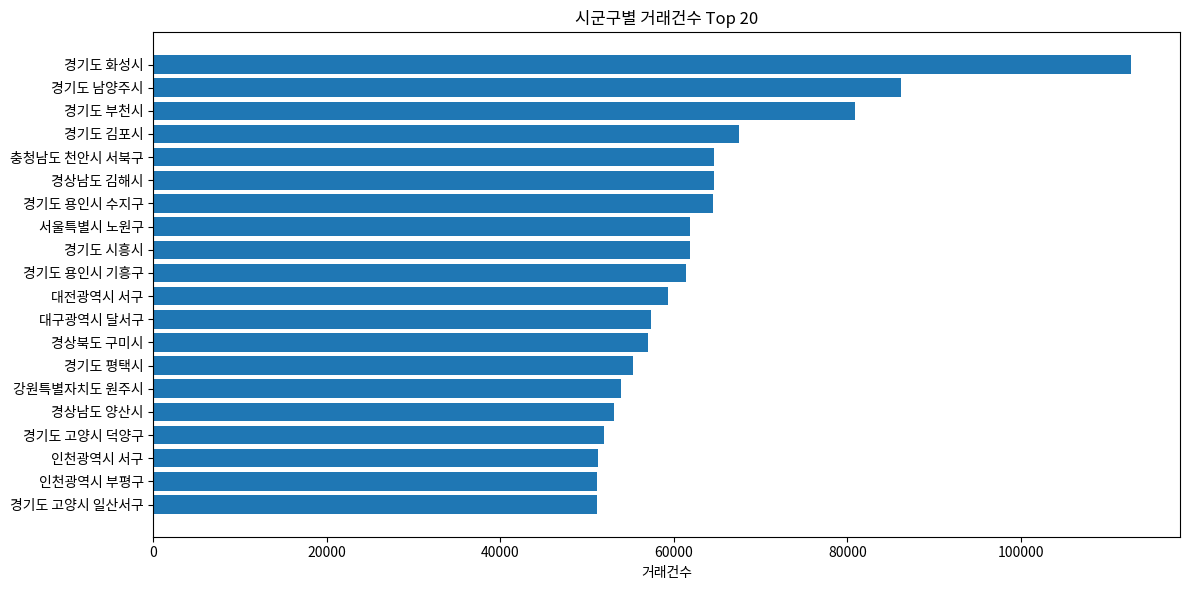

In [8]:
import matplotlib.pyplot as plt

# 거래건수 상위 20개 지역
top_regions = region_count.sort_values(by='거래건수', ascending=False).head(20)

plt.figure(figsize=(12, 6))
plt.barh(top_regions['full_name'][::-1], top_regions['거래건수'][::-1])
plt.xlabel('거래건수')
plt.title('시군구별 거래건수 Top 20')
plt.tight_layout()
plt.show()

시도별 거래비율

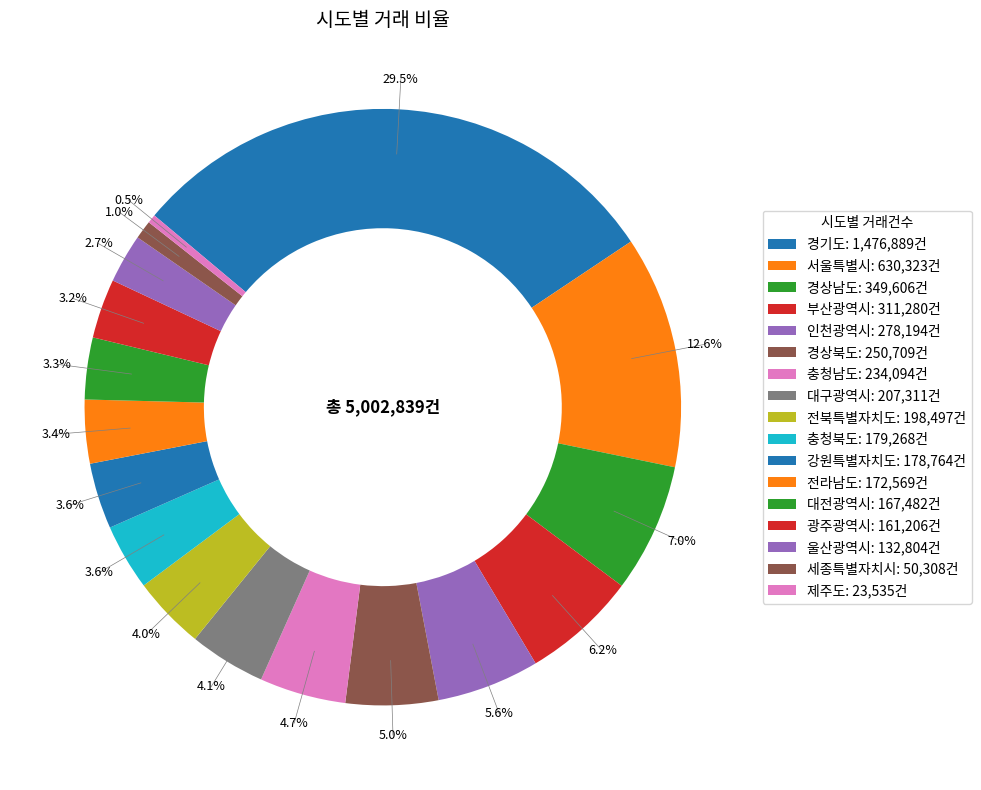

In [9]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# 시도별 거래건수
sido_counts = df['시도명'].value_counts()
total = sido_counts.sum()

# 도넛형 파이차트
fig, ax = plt.subplots(figsize=(10, 8))
wedges, texts = ax.pie(
    sido_counts,
    labels=None,
    startangle=140,
    counterclock=False,
    wedgeprops=dict(width=0.4)
)

for i, wedge in enumerate(wedges):
    theta = (wedge.theta1 + wedge.theta2) / 2
    x = 1.1 * np.cos(np.deg2rad(theta))  
    y = 1.1 * np.sin(np.deg2rad(theta))
    pct = sido_counts.values[i] / total * 100

    ax.text(x, y, f'{pct:.1f}%', ha='center', va='center', fontsize=9)

    x0 = 0.85 * np.cos(np.deg2rad(theta))
    y0 = 0.85 * np.sin(np.deg2rad(theta))
    ax.plot([x0, x], [y0, y], color='gray', linewidth=0.5)

legend_labels = [f'{label}: {val:,}건' for label, val in zip(sido_counts.index, sido_counts.values)]
ax.legend(wedges, legend_labels, title='시도별 거래건수', loc='center left', bbox_to_anchor=(1, 0.5))

ax.text(0, 0, f'총 {total:,}건', ha='center', va='center', fontsize=12, fontweight='bold')

plt.title('시도별 거래 비율', fontsize=14)
plt.tight_layout()
plt.show()

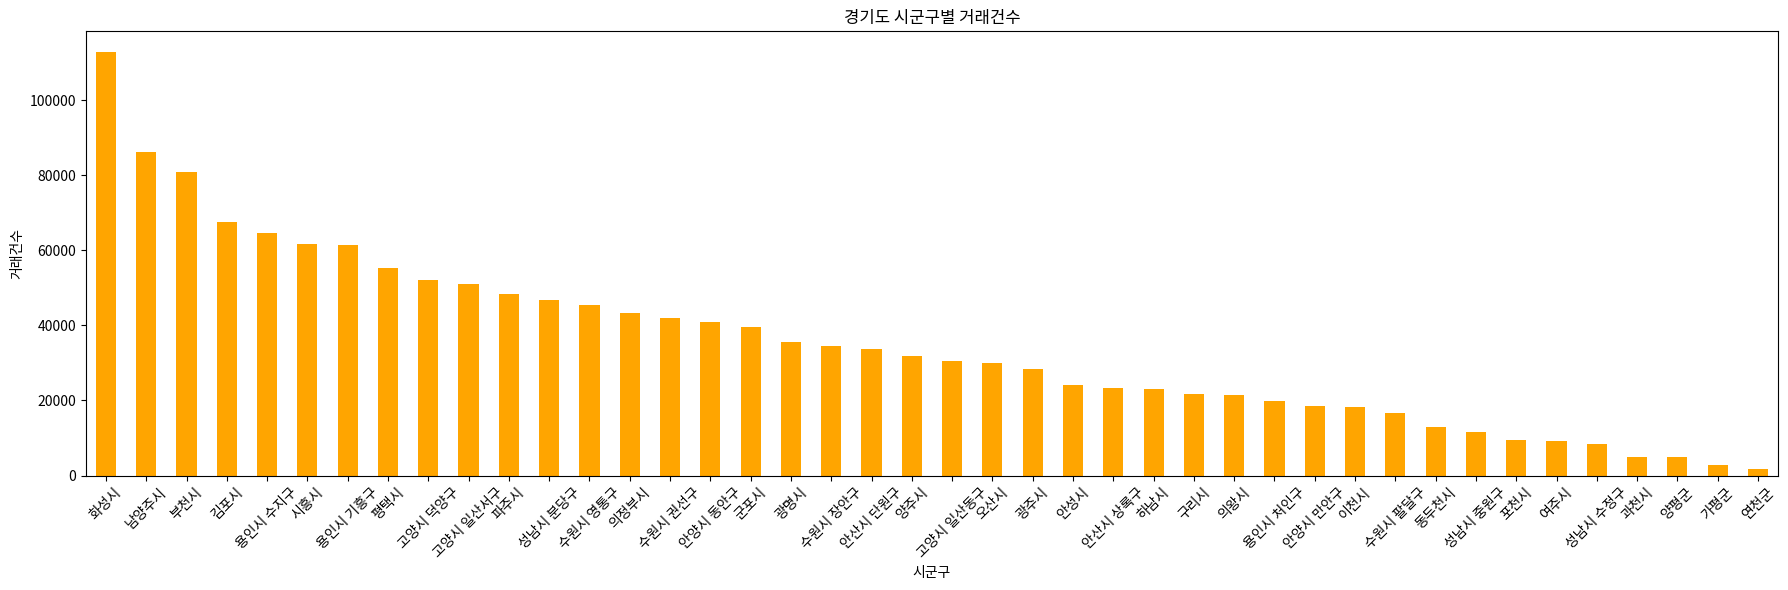

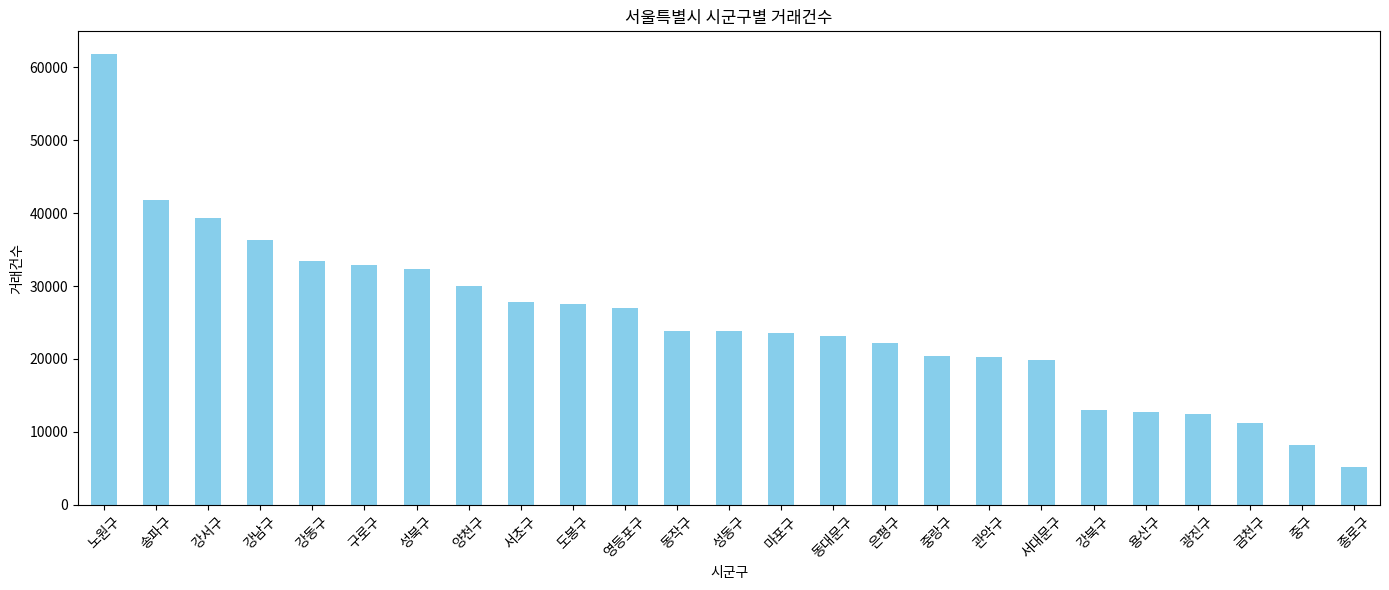

In [10]:
import matplotlib.pyplot as plt

# 경기도 전체 시군구
gyeonggi = df[df['시도명'] == '경기도'].copy()
gyeonggi['시군구만'] = gyeonggi['지역명'].str.replace('경기도 ', '', regex=False)
gyeonggi_counts = gyeonggi['시군구만'].value_counts()

plt.figure(figsize=(18, 6))  
gyeonggi_counts.plot(kind='bar', color='orange')
plt.title('경기도 시군구별 거래건수')
plt.xlabel('시군구')
plt.ylabel('거래건수')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 서울특별시 전체 시군구
seoul = df[df['시도명'] == '서울특별시'].copy()
seoul['시군구만'] = seoul['지역명'].str.replace('서울특별시 ', '', regex=False)
seoul_counts = seoul['시군구만'].value_counts()

plt.figure(figsize=(14, 6))  
seoul_counts.plot(kind='bar', color='skyblue')
plt.title('서울특별시 시군구별 거래건수')
plt.xlabel('시군구')
plt.ylabel('거래건수')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

시계열 분석

월별 거래건수 추이

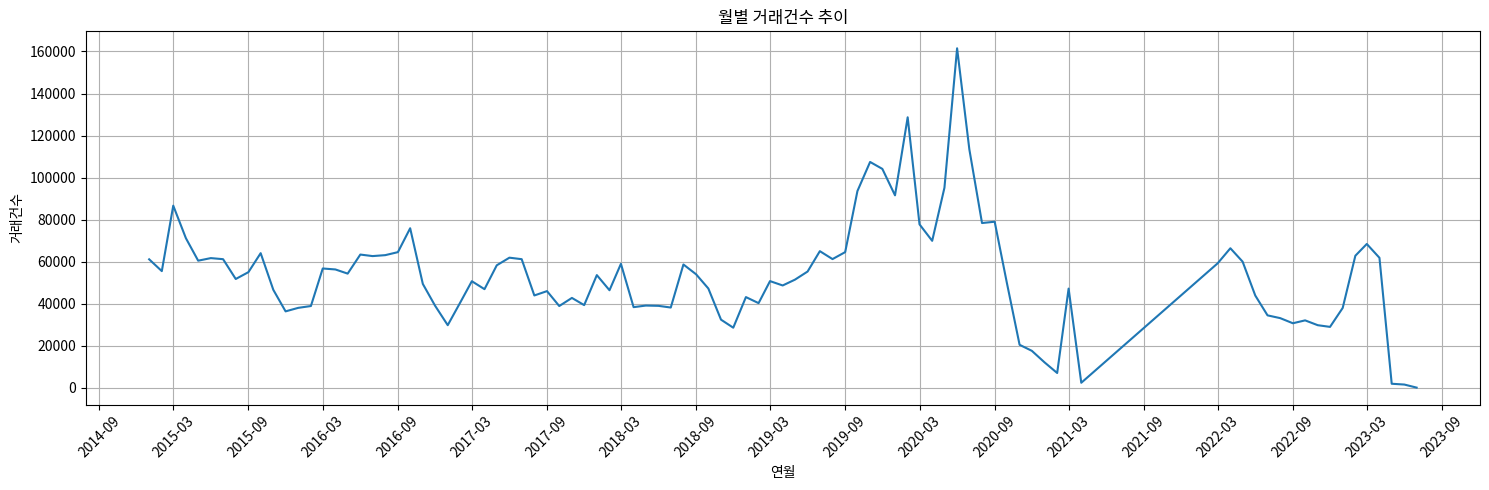

In [11]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

df['연월'] = pd.to_datetime(df['거래일']).dt.to_period('M').dt.to_timestamp()
monthly = df.groupby('연월').size()

plt.figure(figsize=(15, 5))
plt.plot(monthly.index, monthly.values)

# x축 포맷 지정: 월 단위 눈금 + YYYY-MM 형식 라벨
plt.gca().xaxis.set_major_locator(mdates.MonthLocator(interval=6))  # 6개월 간격 눈금
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))

plt.title('월별 거래건수 추이')
plt.xlabel('연월')
plt.ylabel('거래건수')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

월별 평균 거래금액 추이

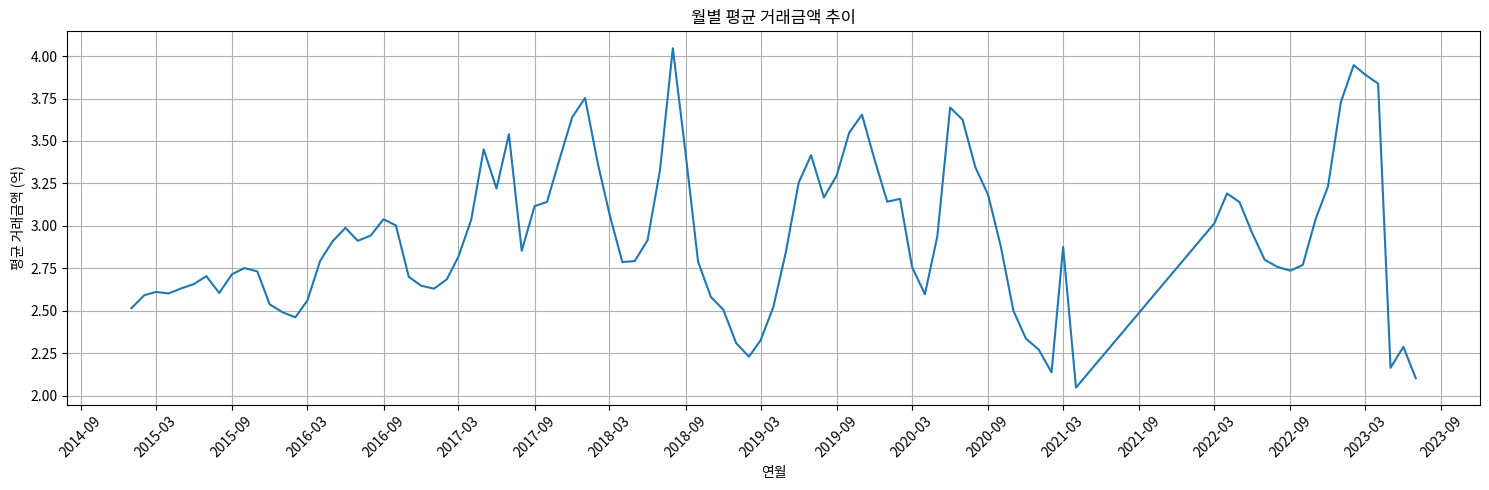

In [12]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# 연월을 datetime 형식으로 정제
df['연월'] = pd.to_datetime(df['거래일']).dt.to_period('M').dt.to_timestamp()

# 월별 평균 거래금액 계산
monthly_price = df.groupby('연월')['거래금액'].mean()

# 그래프 시각화
plt.figure(figsize=(15, 5))
plt.plot(monthly_price.index, monthly_price.values)

# x축 눈금 설정: 6개월 간격 + 라벨 포맷 설정
plt.gca().xaxis.set_major_locator(mdates.MonthLocator(interval=6))
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))

plt.title('월별 평균 거래금액 추이')
plt.xlabel('연월')
plt.ylabel('평균 거래금액 (억)')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

### 3. 가설 수립

가설 1. 전용면적이 클수록 거래금액도 높을 것이다.

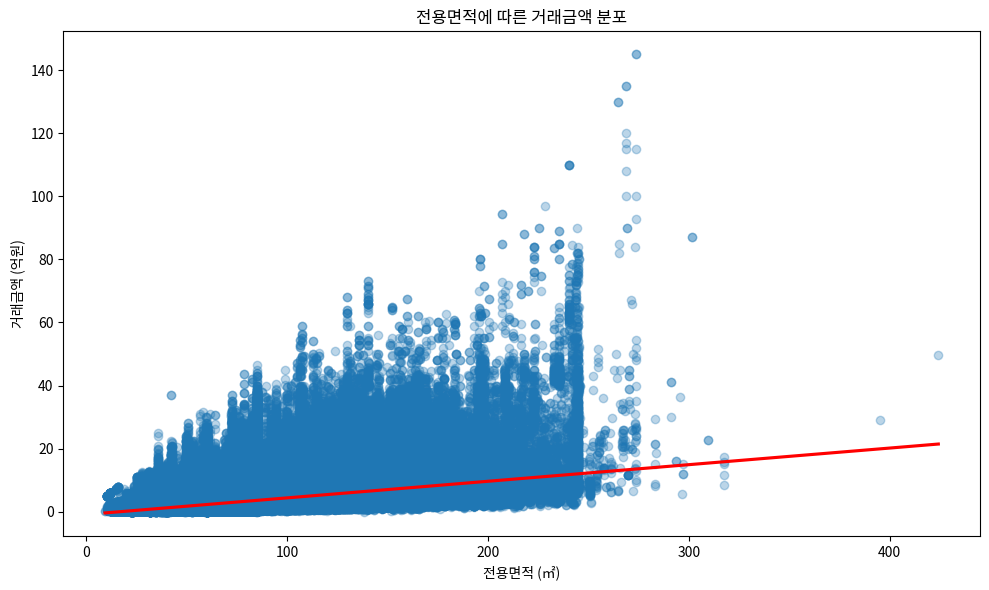

In [13]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
sns.regplot(
    data=df,
    x='전용면적',
    y='거래금액',
    scatter_kws={'alpha': 0.3},
    line_kws={'color': 'red'}
)
plt.title('전용면적에 따른 거래금액 분포')
plt.xlabel('전용면적 (㎡)')
plt.ylabel('거래금액 (억원)')
plt.tight_layout()
plt.show()

In [14]:
corr = df[['전용면적', '거래금액']].corr().iloc[0, 1]
print(f'전용면적과 거래금액 간 상관계수: {corr:.3f}')

전용면적과 거래금액 간 상관계수: 0.479


가설 2. 건축연도가 최근일수록 거래금액이 높을 것이다.

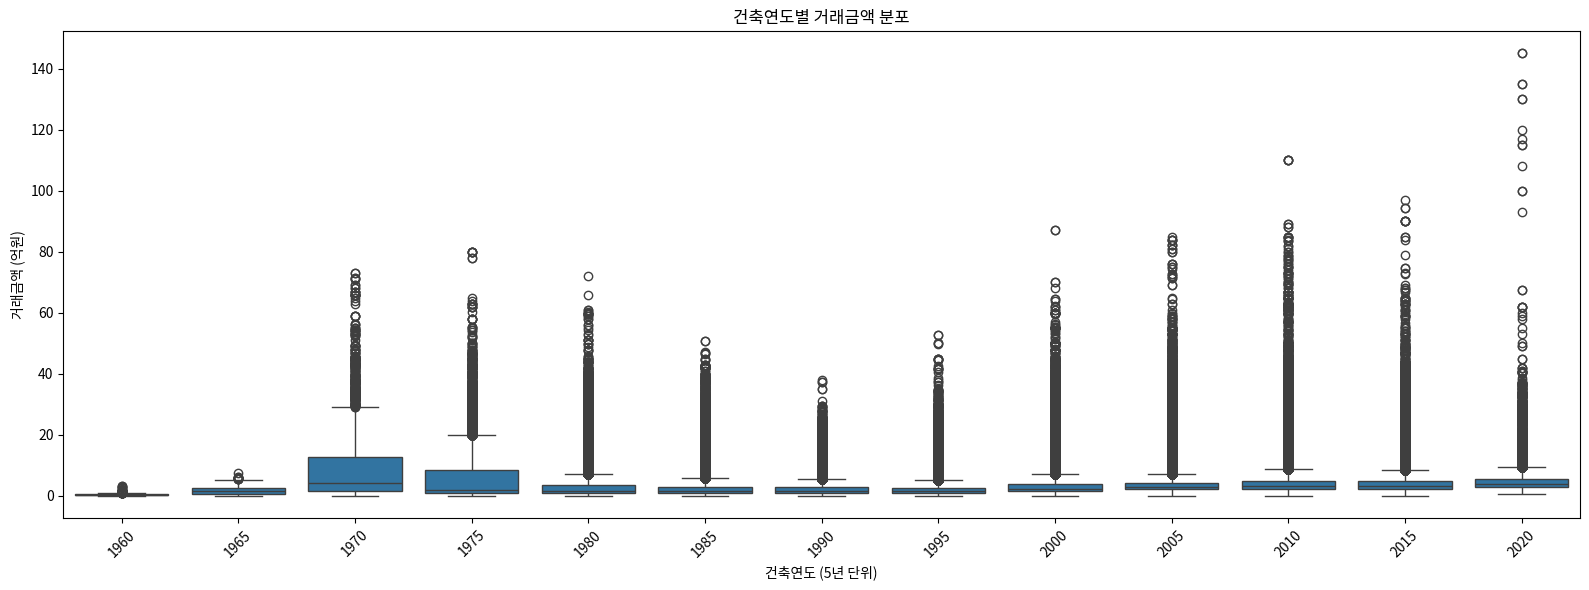

In [15]:
# 건축연도 단위 정리
df['건축연도_5년'] = (df['건축연도'] // 5) * 5  # 5년 단위 그룹

# 박스플롯: 1960년부터
plt.figure(figsize=(16, 6))
sns.boxplot(data=df[df['건축연도'] >= 1960], x='건축연도_5년', y='거래금액')
plt.title('건축연도별 거래금액 분포')
plt.xlabel('건축연도 (5년 단위)')
plt.ylabel('거래금액 (억원)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

가설 3. 지역에 따라 거래금액은 다를 것이다.

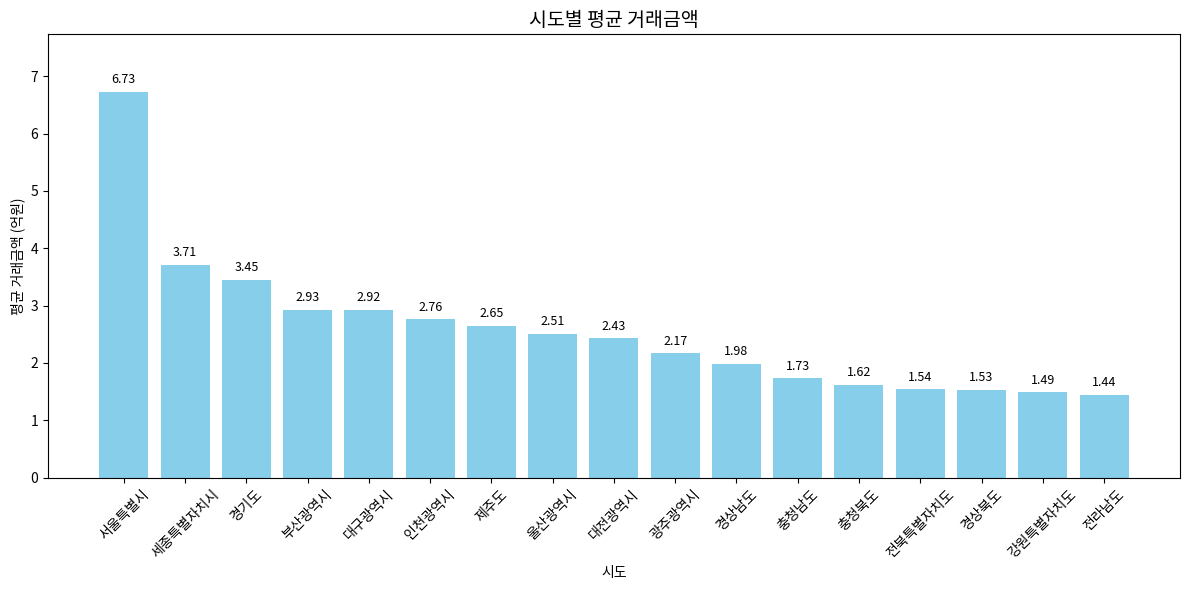

In [16]:
import matplotlib.pyplot as plt

# 정리된 시도별 평균 거래금액 (소수점 2자리로 포맷팅)
mean_by_sido = df.groupby('시도명')['거래금액'].mean().sort_values(ascending=False)
mean_by_sido = mean_by_sido.round(2)

# 그래프
plt.figure(figsize=(12, 6))
bars = plt.bar(mean_by_sido.index, mean_by_sido.values, color='skyblue')

# 숫자 라벨 추가
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, yval + 0.1, f'{yval:.2f}', ha='center', va='bottom', fontsize=9)

plt.title('시도별 평균 거래금액', fontsize=14)
plt.ylabel('평균 거래금액 (억원)')
plt.xlabel('시도')
plt.xticks(rotation=45)
plt.ylim(0, mean_by_sido.max() + 1)
plt.tight_layout()
plt.show()

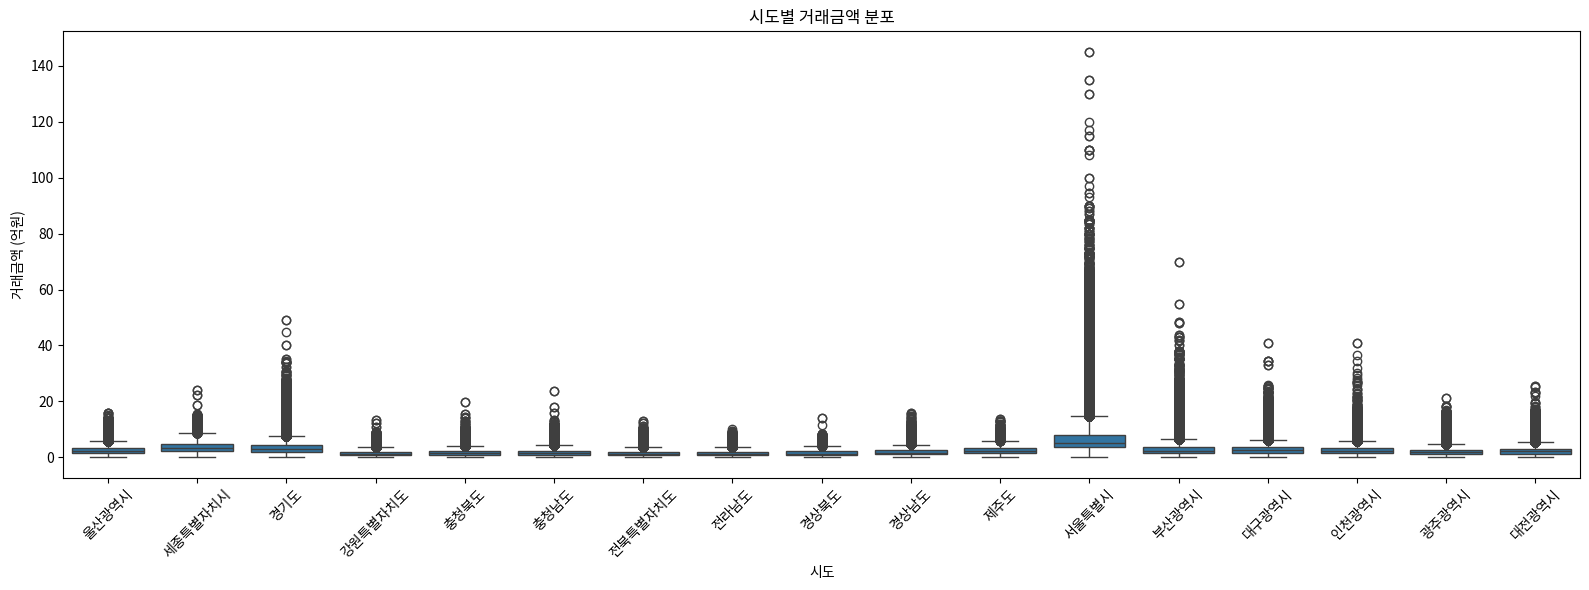

In [17]:
plt.figure(figsize=(16, 6))
sns.boxplot(data=df, x='시도명', y='거래금액')
plt.title('시도별 거래금액 분포')
plt.xlabel('시도')
plt.ylabel('거래금액 (억원)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

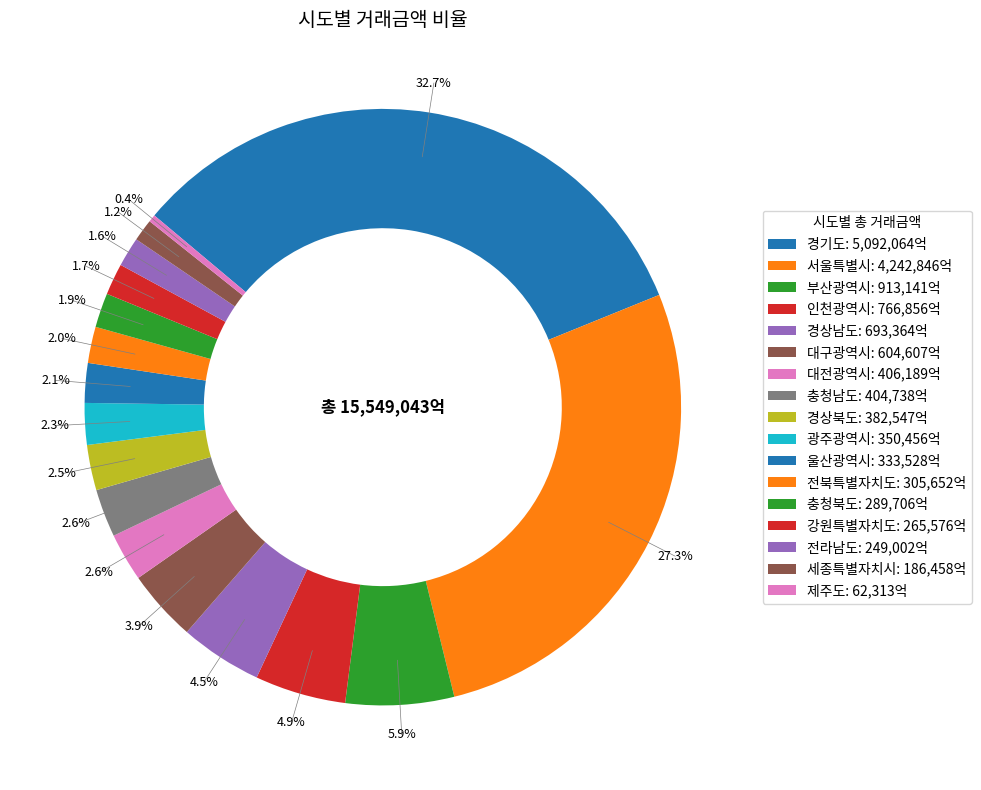

In [18]:
import matplotlib.pyplot as plt
import numpy as np

# 시도별 총 거래금액 계산
sido_amounts = df.groupby('시도명')['거래금액'].sum().sort_values(ascending=False)
total_amount = sido_amounts.sum()

# 도넛형 파이차트
fig, ax = plt.subplots(figsize=(10, 8))
wedges, texts = ax.pie(
    sido_amounts,
    labels=None,
    startangle=140,
    counterclock=False,
    wedgeprops=dict(width=0.4)
)

for i, wedge in enumerate(wedges):
    theta = (wedge.theta1 + wedge.theta2) / 2
    x = 1.1 * np.cos(np.deg2rad(theta))
    y = 1.1 * np.sin(np.deg2rad(theta))
    pct = sido_amounts.values[i] / total_amount * 100

    ax.text(x, y, f'{pct:.1f}%', ha='center', va='center', fontsize=9)

    x0 = 0.85 * np.cos(np.deg2rad(theta))
    y0 = 0.85 * np.sin(np.deg2rad(theta))
    ax.plot([x0, x], [y0, y], color='gray', linewidth=0.5)

legend_labels = [f'{label}: {amt:,.0f}억' for label, amt in zip(sido_amounts.index, sido_amounts.values)]
ax.legend(wedges, legend_labels, title='시도별 총 거래금액', loc='center left', bbox_to_anchor=(1, 0.5))

ax.text(0, 0, f'총 {int(total_amount):,}억', ha='center', va='center', fontsize=12, fontweight='bold')

plt.title('시도별 거래금액 비율', fontsize=14)
plt.tight_layout()
plt.show()

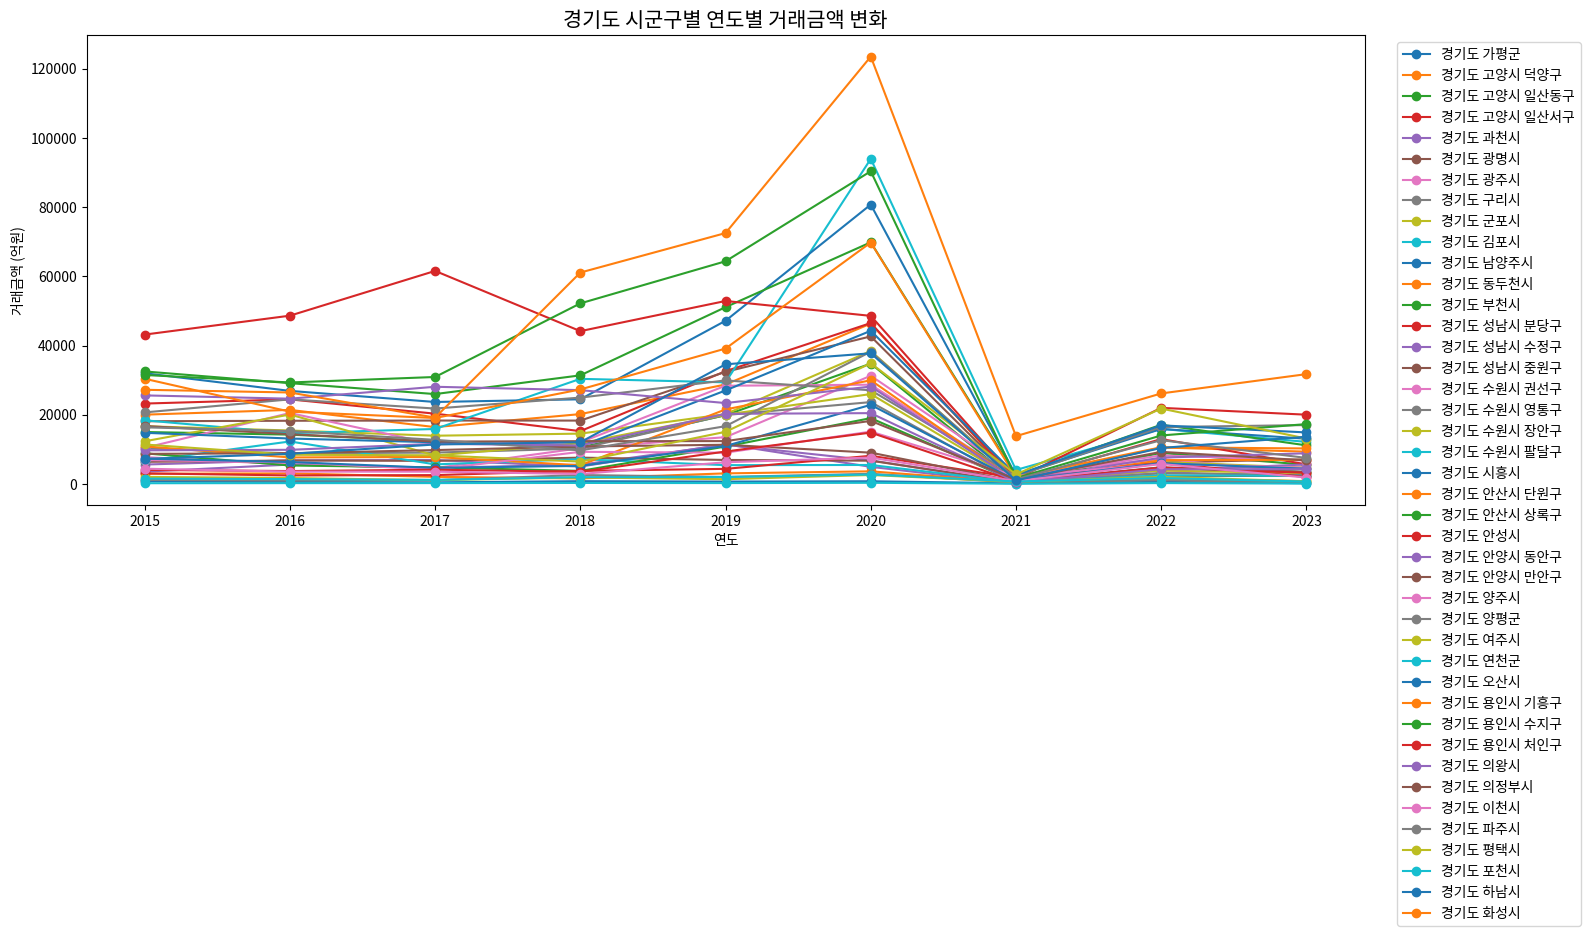

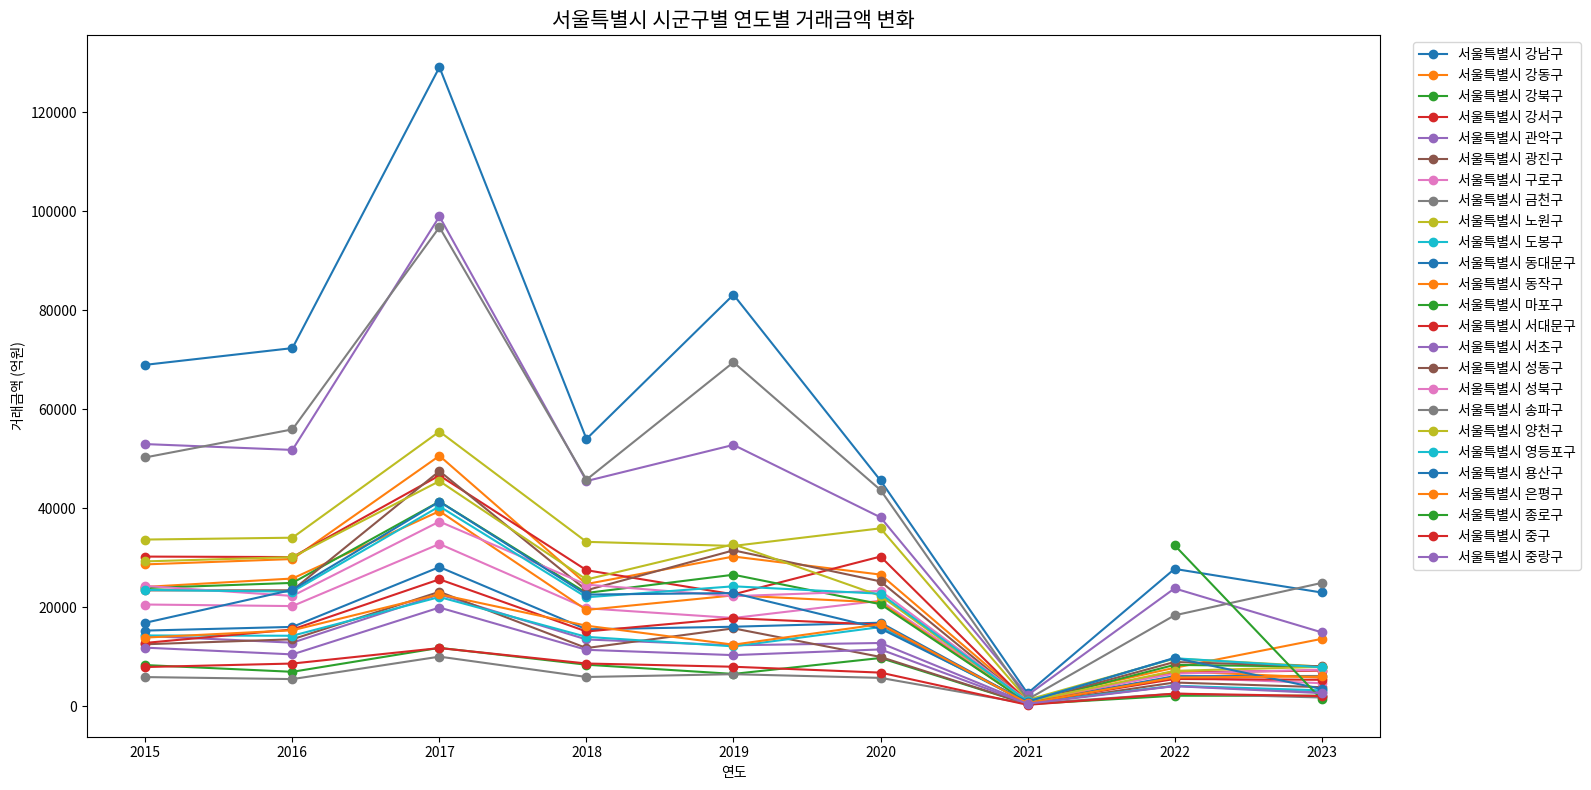

In [19]:
def plot_region_yearly_amount_trend(sido_name, top_n=None):
    # 해당 시도 필터
    df_sido = df[df['시도명'] == sido_name].copy()

    # 연도별 지역별 거래금액 총합
    grouped = df_sido.groupby(['연도', '지역명'])['거래금액'].sum().reset_index()

    pivot = grouped.pivot(index='연도', columns='지역명', values='거래금액')

    # 시각화
    plt.figure(figsize=(16, 8))
    for col in pivot.columns:
        plt.plot(pivot.index, pivot[col], marker='o', label=col)

    plt.title(f'{sido_name} 시군구별 연도별 거래금액 변화', fontsize=15)
    plt.xlabel('연도')
    plt.ylabel('거래금액 (억원)')
    plt.xticks(pivot.index)
    plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
    plt.tight_layout()
    plt.show()

# 예시 실행: 경기도
plot_region_yearly_amount_trend('경기도')

# 예시 실행: 서울
plot_region_yearly_amount_trend('서울특별시')

가설 4. 층수는 중간층일수록 거래금액이 높을 것이다.

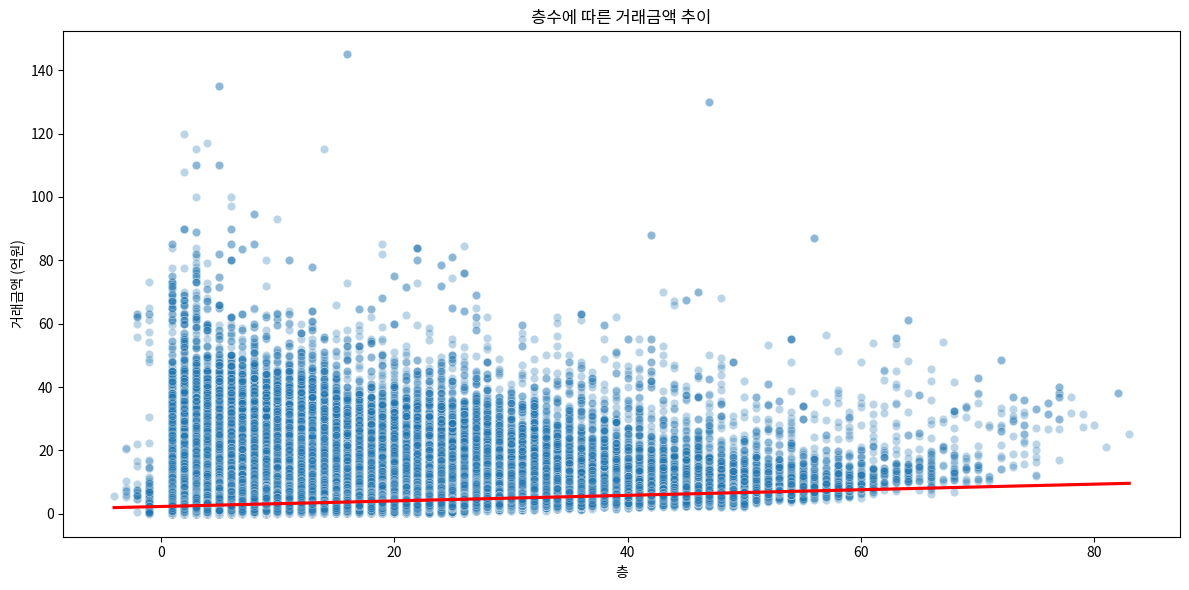

In [20]:
# 층 컬럼을 수치형으로 변환 
df['층'] = pd.to_numeric(df['층'], errors='coerce')

plt.figure(figsize=(12, 6))
sns.scatterplot(data=df, x='층', y='거래금액', alpha=0.3)
sns.regplot(data=df, x='층', y='거래금액', scatter=False, color='red')
plt.title('층수에 따른 거래금액 추이') 
plt.xlabel('층')
plt.ylabel('거래금액 (억원)')
plt.tight_layout()
plt.show()

In [21]:
# 층수 기준 분위수 구하기
q1 = df['층'].quantile(0.25)
q2 = df['층'].quantile(0.5)
q3 = df['층'].quantile(0.75)

print(f"1사분위수: {q1:.0f}층 / 중위수: {q2:.0f}층 / 3사분위수: {q3:.0f}층")

1사분위수: 4층 / 중위수: 8층 / 3사분위수: 13층


In [22]:
def categorize_floor_quantile(floor):
    if pd.isna(floor): return '기타'
    if floor <= 4:
        return '저층'
    elif floor <= 13:
        return '중층'
    else:
        return '고층'

df['층구간'] = df['층'].apply(categorize_floor_quantile)

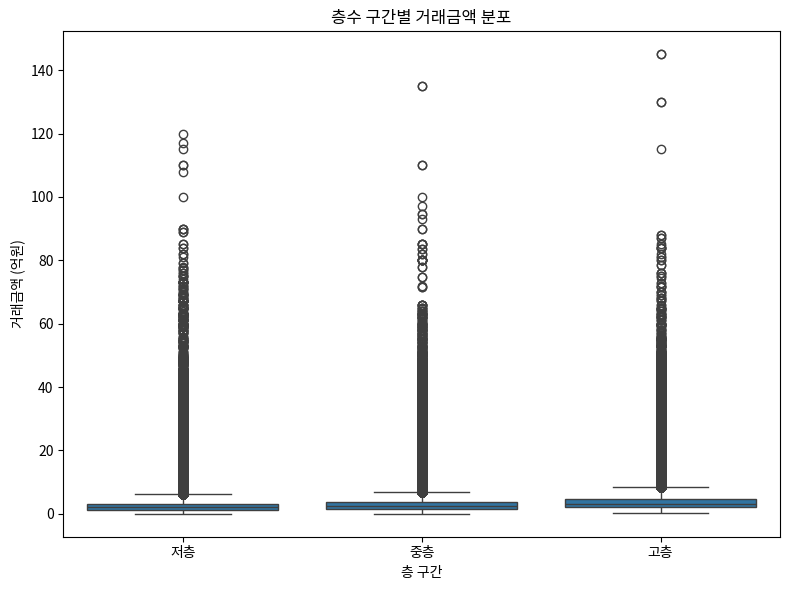

층구간별 평균 거래금액 (억원):
층구간
저층    2.64
중층    3.04
고층    3.82
Name: 거래금액, dtype: float64


In [23]:
plt.figure(figsize=(8, 6))
sns.boxplot(data=df, x='층구간', y='거래금액', order=['저층', '중층', '고층'])
plt.title('층수 구간별 거래금액 분포')
plt.xlabel('층 구간')
plt.ylabel('거래금액 (억원)')
plt.tight_layout()
plt.show()

층별_평균 = df.groupby('층구간')['거래금액'].mean().loc[['저층', '중층', '고층']]
print('층구간별 평균 거래금액 (억원):')
print(층별_평균.round(2))

가설 5. 구축연차가 짧을수록 아파트의 거래금액이 높을 것이다.

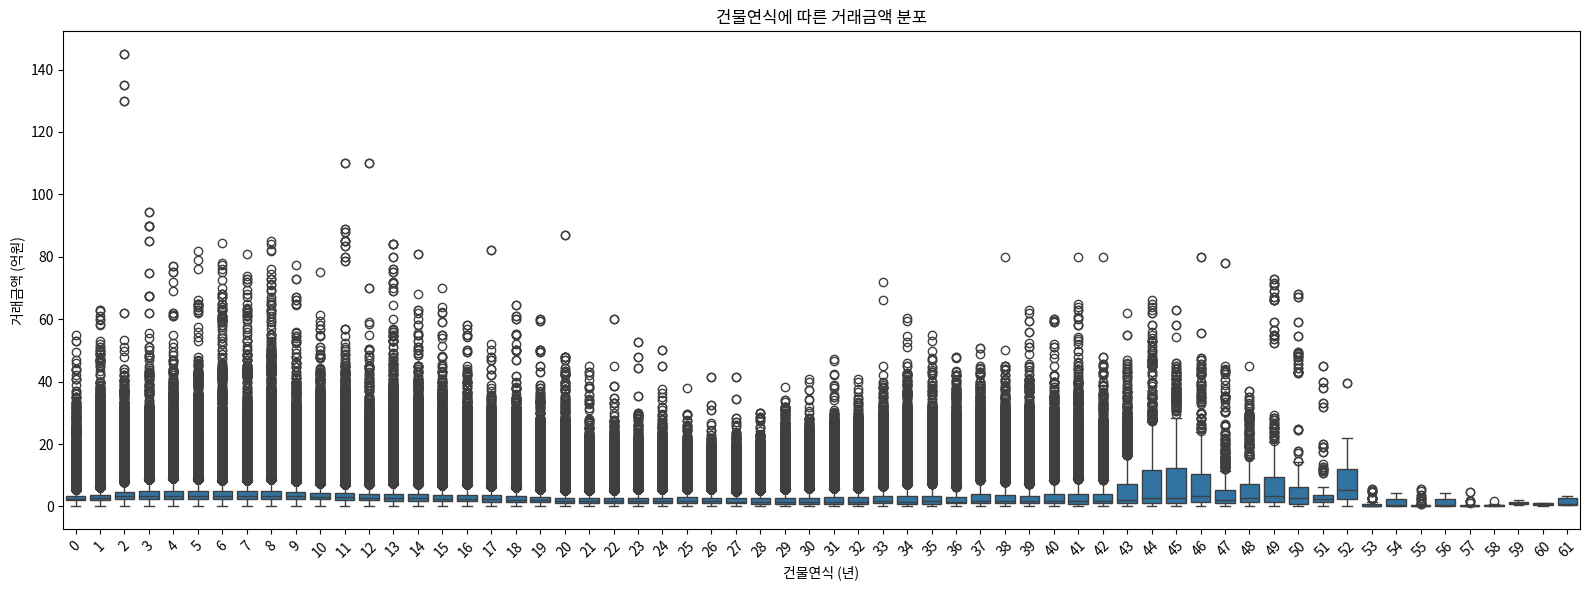

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

# 건물연식 = 거래연도 - 건축연도
df['건물연식'] = df['연도'] - df['건축연도']

# 음수 제거 (건축연도가 미래인 경우 등)
df = df[df['건물연식'] >= 0]

# 시각화
plt.figure(figsize=(16, 6))
sns.boxplot(data=df, x='건물연식', y='거래금액')
plt.title('건물연식에 따른 거래금액 분포')
plt.xlabel('건물연식 (년)')
plt.ylabel('거래금액 (억원)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

가설 6. 평균소득이 높은 지역일수록 거래금액이 높을 것이다.

외부 변수 추가 - 평균소득월액

In [ ]:
import pandas as pd
import re
import numpy as np

# 소득 데이터 로드
income_path = '/home/yu_jh/jihye/ji/jihye/s_project/data/국민연금공단_자격 시구신고 평균소득월액_20250131.csv'
income_df = pd.read_csv(income_path, encoding='cp949')

# 열 이름 정리 및 변경
income_df.columns = income_df.columns.str.strip()
income_df = income_df.rename(columns={'시군구': '지역명', '평균소득월액': '평균소득'})

# 지역명 정제: '시도 시군구' 형태 맞추기
def split_sido_sgg(name):
    match = re.match(r'([가-힣]+도|서울특별시|부산광역시|대구광역시|인천광역시|광주광역시|대전광역시|울산광역시|세종특별자치시|제주특별자치도|강원특별자치도|전북특별자치도)(.+)', name)
    if match:
        sido = match.group(1).strip()
        sgg = match.group(2).strip()
        sgg_match = re.match(r'(.+?(시|군|구))(.+)', sgg)
        if sgg_match:
            sgg = sgg_match.group(1) + ' ' + sgg_match.group(3)
        return f'{sido} {sgg}'
    return name

income_df['지역명'] = income_df['지역명'].apply(split_sido_sgg)

# 시단위로 줄이기
def reduce_to_city(name):
    match = re.match(r'(.+?(시|군))', name)
    return match.group(1) if match else name

df2 = df.copy()
df2['시단위지역명'] = df2['지역명'].apply(reduce_to_city)
income_df['시단위지역명'] = income_df['지역명'].apply(reduce_to_city)

# 병합
df2 = df2.merge(income_df[['시단위지역명', '평균소득']], on='시단위지역명', how='left')

# 제주지역 직접 매핑
jejudo_map = {
    '제주도 제주시': '제주특별자치도 제주시',
    '제주도 서귀포시': '제주특별자치도 서귀포시'
}

for old, new in jejudo_map.items():
    income = income_df.loc[income_df['지역명'] == new, '평균소득']
    if not income.empty:
        df2.loc[df2['지역명'] == old, '평균소득'] = income.values[0]

# 시도 기준 평균소득 계산 → 남은 결측치 대체
sido_income_mean = df2.groupby('시도명')['평균소득'].mean()

def fill_missing_income(row):
    if pd.isna(row['평균소득']):
        return sido_income_mean.get(row['시도명'], np.nan)
    return row['평균소득']

df2['평균소득'] = df2.apply(fill_missing_income, axis=1)

# 소득 단위 변환: 원 → 만원, 소수점 없이 정수 처리
df2['평균소득'] = (df2['평균소득'] / 10000).astype(int)

df2.drop(columns=['시단위지역명'], inplace=True)

# df2 데이터프레임 생성
df2.head()

,지역코드,법정동,거래일,아파트,지번,전용면적,층,건축연도,거래금액,시도명,시군구명,지역명,연도,연월,건축연도_5년,층구간,건물연식,평균소득
0,31110,학성동,2020-05-30,남운학성타운,379,135.58,8.0,1991,2.67,울산광역시,중구,울산광역시 중구,2020,2020-05-01,1990,중층,29,136
1,31110,학성동,2020-05-30,남운학성타운,379,135.58,8.0,1991,2.67,울산광역시,중구,울산광역시 중구,2020,2020-05-01,1990,중층,29,144
2,31110,학성동,2020-05-30,남운학성타운,379,135.58,8.0,1991,2.67,울산광역시,중구,울산광역시 중구,2020,2020-05-01,1990,중층,29,130
3,31110,학성동,2020-05-30,남운학성타운,379,135.58,8.0,1991,2.67,울산광역시,중구,울산광역시 중구,2020,2020-05-01,1990,중층,29,138
4,31110,학성동,2020-05-30,남운학성타운,379,135.58,8.0,1991,2.67,울산광역시,중구,울산광역시 중구,2020,2020-05-01,1990,중층,29,143


시군구별 평균소득과 거래금액의 피어슨 상관계수: 0.554


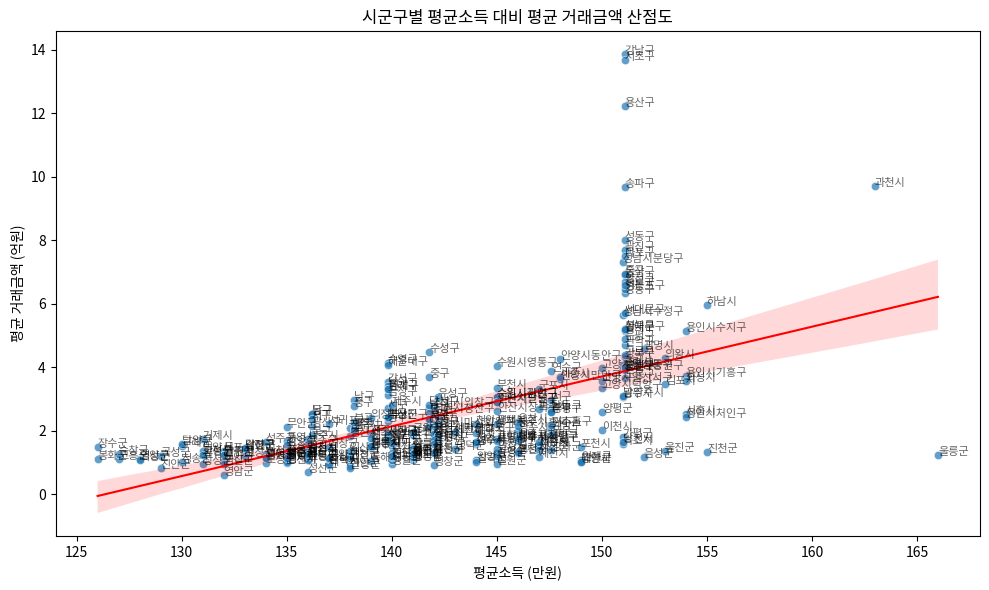

In [26]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

plt.rc('font', family='Noto Sans CJK JP')
plt.rcParams['axes.unicode_minus'] = False

# 숫자형 변환
df2['평균소득'] = pd.to_numeric(df2['평균소득'], errors='coerce')
df2['거래금액'] = pd.to_numeric(df2['거래금액'], errors='coerce')

# 결측치 제거
df_clean = df2[['시도명', '시군구명', '평균소득', '거래금액']].dropna()

# 시군구별 평균값 집계
df_grouped = df_clean.groupby(['시도명', '시군구명'], as_index=False).agg({
    '평균소득': 'mean',
    '거래금액': 'mean'
})

# 상관계수 확인
corr = df_grouped['평균소득'].corr(df_grouped['거래금액'])
print(f"시군구별 평균소득과 거래금액의 피어슨 상관계수: {corr:.3f}")

# 산점도 그리기
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df_grouped,
    x='평균소득',
    y='거래금액',
    alpha=0.7
)
sns.regplot(
    data=df_grouped,
    x='평균소득',
    y='거래금액',
    scatter=False,
    color='red',
    line_kws={'linewidth': 1.5}
)

for _, row in df_grouped.iterrows():
    plt.text(row['평균소득'], row['거래금액'], row['시군구명'], fontsize=8, alpha=0.6)

plt.title('시군구별 평균소득 대비 평균 거래금액 산점도')
plt.xlabel('평균소득 (만원)')
plt.ylabel('평균 거래금액 (억원)')
plt.tight_layout()
plt.show()

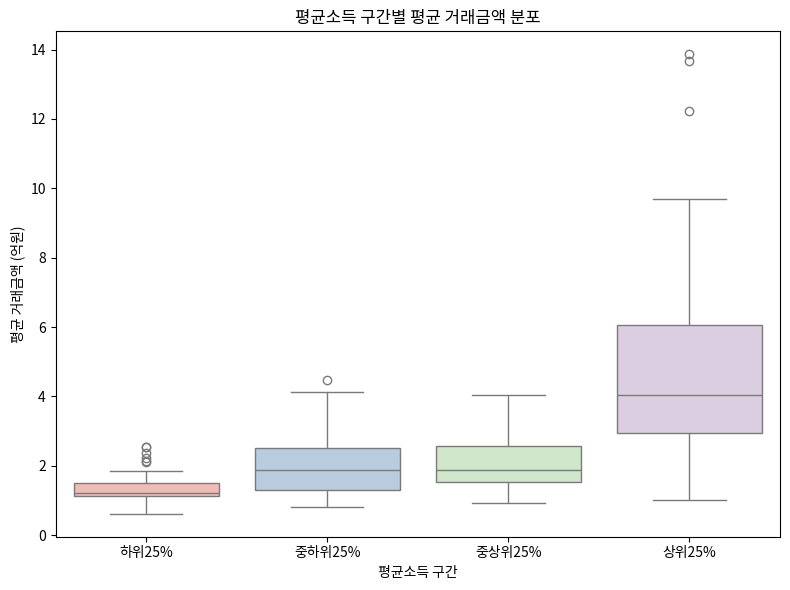

소득구간별 평균 거래금액 (억원):
소득구간
하위25%     1.35
중하위25%    2.05
중상위25%    2.03
상위25%     4.70
Name: 거래금액, dtype: float64


In [27]:
plt.rc('font', family='Noto Sans CJK JP')
plt.rcParams['axes.unicode_minus'] = False

# 시군구별 평균소득/거래금액 구하기 (앞서 했던 것)
df_grouped = df2[['시도명', '시군구명', '평균소득', '거래금액']].dropna().groupby(['시도명', '시군구명'], as_index=False).mean()

# 4분위 구간 생성
df_grouped['소득구간'] = pd.qcut(df_grouped['평균소득'], q=4, labels=['하위25%', '중하위25%', '중상위25%', '상위25%'])

# 박스플롯 시각화
plt.figure(figsize=(8, 6))
sns.boxplot(
    data=df_grouped,
    x='소득구간',
    y='거래금액',
    order=['하위25%', '중하위25%', '중상위25%', '상위25%'],
    palette='Pastel1'
)

plt.title('평균소득 구간별 평균 거래금액 분포')
plt.xlabel('평균소득 구간')
plt.ylabel('평균 거래금액 (억원)')
plt.tight_layout()
plt.show()

# 평균 출력
print("소득구간별 평균 거래금액 (억원):")
print(df_grouped.groupby('소득구간')['거래금액'].mean().round(2))

### 4. 예측 모델 구축 및 성능 비교

In [28]:
import pandas as pd
import numpy as np
from sklearn.model_selection import KFold
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error
)
import xgboost as xgb
import lightgbm as lgb

# 모델에 사용할 피처 및 타깃 정의
features = ['전용면적', '건축연도', '층', '연도', '지역명', '평균소득', '건물연식']
target   = '거래금액'

# 결측치 제거 후 X, y 분리
model_df = df2[features + [target]].dropna()
X = model_df[features].reset_index(drop=True)
y = model_df[target].reset_index(drop=True)

# 전처리 파이프라인 정의
numeric_features     = ['전용면적', '건축연도', '층', '연도', '건물연식', '평균소득']
categorical_features = ['지역명']

preprocessor = ColumnTransformer(transformers=[
    ('num', SimpleImputer(strategy='mean'),   numeric_features),
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
])

# 모델별 Pipeline 정의 (트리 수, 깊이 최적화)
pipelines = {
    'LinearRegression': Pipeline([
        ('preprocessor', preprocessor),
        ('regressor', LinearRegression())
    ]),
    'DecisionTree': Pipeline([
        ('preprocessor', preprocessor),
        ('regressor', DecisionTreeRegressor(max_depth=6, random_state=42))
    ]),
    'RandomForest': Pipeline([
        ('preprocessor', preprocessor),
        ('regressor', RandomForestRegressor(
            n_estimators=50,    # 100 → 50
            max_depth=8,        # 10 → 8
            random_state=42,
            n_jobs=-2           # 가용 코어 수 −1
        ))
    ]),
    'XGBoost': Pipeline([
        ('preprocessor', preprocessor),
        ('regressor', xgb.XGBRegressor(
            objective='reg:squarederror',
            n_estimators=50,    # 100 → 50
            learning_rate=0.1,
            max_depth=6,
            random_state=42,
            n_jobs=-2
        ))
    ]),
    'LightGBM': Pipeline([
        ('preprocessor', preprocessor),
        ('regressor', lgb.LGBMRegressor(
            n_estimators=50,    # 100 → 50
            learning_rate=0.1,
            max_depth=8,        # 10 → 8
            random_state=42,
            n_jobs=-2
        ))
    ])
}

# 평가 지표 계산 함수
def compute_metrics(y_true, y_pred):
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mape = mean_absolute_percentage_error(y_true, y_pred)
    return mae, rmse, mape

# 10-Fold CV 설정
cv = KFold(n_splits=10, shuffle=True, random_state=42)

# 모델별 CV 수동 수행 및 로그 출력
results = {}

for model_name, pipeline in pipelines.items():
    print(f"\n=== [{model_name}] 10-Fold CV 시작 ===")
    
    # 폴드별 지표 저장용 리스트
    mae_list  = []
    rmse_list = []
    mape_list = []
    
    for fold_idx, (train_idx, test_idx) in enumerate(cv.split(X), start=1):
        print(f"-- {model_name} Fold {fold_idx}/10 시작 --")
        
        # train/test 분리
        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
        
        # 모델 학습
        pipeline.fit(X_train, y_train)
        
        # 예측
        y_pred = pipeline.predict(X_test)
        
        # 지표 계산
        mae_val, rmse_val, mape_val = compute_metrics(y_test, y_pred)
        mae_list.append(mae_val)
        rmse_list.append(rmse_val)
        mape_list.append(mape_val)
        
        print(f"-- {model_name} Fold {fold_idx}/10 완료: "
              f"MAE={mae_val:.4f}, RMSE={rmse_val:.4f}, MAPE={mape_val:.4f} --")
    
    # 폴드별 평균, 표준편차 계산
    results[model_name] = {
        'MAE_mean':  np.mean(mae_list),
        'MAE_std':   np.std(mae_list),
        'RMSE_mean': np.mean(rmse_list),
        'RMSE_std':  np.std(rmse_list),
        'MAPE_mean': np.mean(mape_list),
        'MAPE_std':  np.std(mape_list)
    }
    
    print(f"=== [{model_name}] 10-Fold CV 완료 ===")
    print(f"평균 MAE  = {results[model_name]['MAE_mean']:.4f} ± {results[model_name]['MAE_std']:.4f}")
    print(f"평균 RMSE = {results[model_name]['RMSE_mean']:.4f} ± {results[model_name]['RMSE_std']:.4f}")
    print(f"평균 MAPE = {results[model_name]['MAPE_mean']:.4f} ± {results[model_name]['MAPE_std']:.4f}")

# 최종 결과 요약 출력
print("\n=== 모든 모델 CV 요약 결과 ===")
for model_name, res in results.items():
    print(f"\n[{model_name}]")
    print(f"  MAE  : {res['MAE_mean']:.4f} ± {res['MAE_std']:.4f}")
    print(f"  RMSE : {res['RMSE_mean']:.4f} ± {res['RMSE_std']:.4f}")
    print(f"  MAPE : {res['MAPE_mean']:.4f} ± {res['MAPE_std']:.4f}")


=== [LinearRegression] 10-Fold CV 시작 ===
-- LinearRegression Fold 1/10 시작 --
-- LinearRegression Fold 1/10 완료: MAE=1.5060, RMSE=2.5466, MAPE=0.4341 --
-- LinearRegression Fold 2/10 시작 --
-- LinearRegression Fold 2/10 완료: MAE=1.5063, RMSE=2.5477, MAPE=0.4334 --
-- LinearRegression Fold 3/10 시작 --
-- LinearRegression Fold 3/10 완료: MAE=1.5041, RMSE=2.5309, MAPE=0.4331 --
-- LinearRegression Fold 4/10 시작 --
-- LinearRegression Fold 4/10 완료: MAE=1.5060, RMSE=2.5456, MAPE=0.4341 --
-- LinearRegression Fold 5/10 시작 --
-- LinearRegression Fold 5/10 완료: MAE=1.5059, RMSE=2.5435, MAPE=0.4330 --
-- LinearRegression Fold 6/10 시작 --
-- LinearRegression Fold 6/10 완료: MAE=1.5041, RMSE=2.5414, MAPE=0.4324 --
-- LinearRegression Fold 7/10 시작 --
-- LinearRegression Fold 7/10 완료: MAE=1.5042, RMSE=2.5365, MAPE=0.4336 --
-- LinearRegression Fold 8/10 시작 --
-- LinearRegression Fold 8/10 완료: MAE=1.5059, RMSE=2.5494, MAPE=0.4329 --
-- LinearRegression Fold 9/10 시작 --
-- LinearRegression Fold 9/10 완료: MAE=1.50

### 5. 설명 가능한 인공지능 (XAI) 기법

LightGBM 모델 선택

In [29]:
# 최종 LightGBM 모델 재학습
best_pipeline = pipelines['LightGBM']
best_pipeline.fit(X, y) 

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.098667 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 986
[LightGBM] [Info] Number of data points in the train set: 30728935, number of used features: 252
[LightGBM] [Info] Start training from score 4.761673


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', SimpleImputer(),
                                                  ['전용면적', '건축연도', '층', '연도',
                                                   '건물연식', '평균소득']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['지역명'])])),
                ('regressor',
                 LGBMRegressor(max_depth=8, n_estimators=50, n_jobs=-2,
                               random_state=42))])

Feature Importance

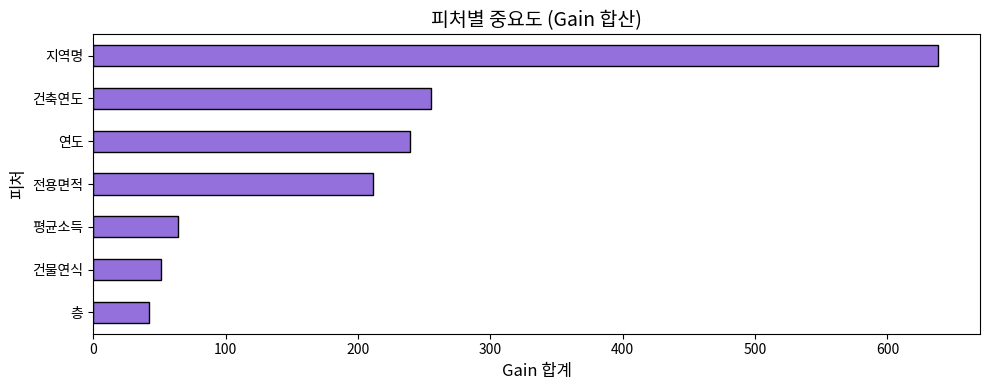

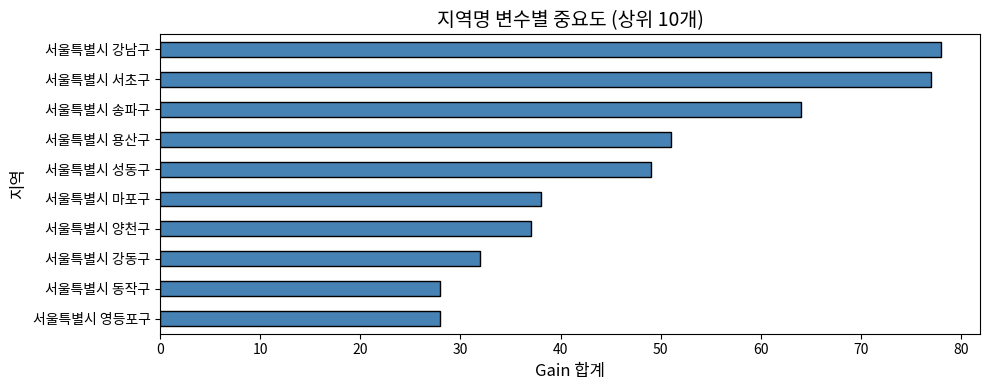

In [30]:
import pandas as pd
import matplotlib.pyplot as plt

# best_pipeline에서 LightGBM 모델 꺼내기
lgbm_model = best_pipeline.named_steps['regressor']

# 전처리 후 최종 피처명 리스트 (숫자형 + OneHot으로 생성된 지역명)
numeric_features = ['전용면적', '건축연도', '층', '연도', '평균소득', '건물연식']

cat_encoder = best_pipeline.named_steps['preprocessor'].named_transformers_['cat']
cats = cat_encoder.categories_[0]  # 예: ['서울특별시 강남구', '서울특별시 서초구', …]
cat_feature_names = [f"지역명_{c}" for c in cats]

final_feature_names = numeric_features + cat_feature_names

# LightGBM 모델 feature_importances_를 Series로 만들고 내림차순 정렬
importances = pd.Series(
    lgbm_model.feature_importances_,
    index=final_feature_names
).sort_values(ascending=False)

# ────────────────────────────────────────────────────────────────────────────────

# A) 전체 피처별(Gain 합산) 중요도 시각화

# ‘지역명_’으로 시작하는 뮤어 변수 전체 합산
region_importances = importances[importances.index.str.startswith("지역명_")]
region_total = region_importances.sum()

# 숫자형 피처 각각의 중요도 추출
numeric_importances = importances[numeric_features]

# “지역명(전체)” + 숫자형 피처를 하나로 합쳐서 Series 생성
agg_dict = {'지역명': region_total}
for feat in numeric_features:
    agg_dict[feat] = numeric_importances.get(feat, 0)
agg_series = pd.Series(agg_dict).sort_values(ascending=False)

# 막대 그래프 그리기 
plt.figure(figsize=(10, 4))
agg_series.plot(
    kind='barh',
    color='mediumpurple',
    edgecolor='black'
)
plt.gca().invert_yaxis()  
plt.title("피처별 중요도 (Gain 합산)", fontsize=14)
plt.xlabel("Gain 합계", fontsize=12)
plt.ylabel("피처", fontsize=12)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)
plt.tight_layout()
plt.show()

# ────────────────────────────────────────────────────────────────────────────────
# B) 지역명 더미 변수 Top 10 중요도 시각화

# Top 10개 뽑기
top10_region = region_importances.head(10)

# 인덱스(레이블)에서 “지역명_” 접두사 제거
top10_region.index = top10_region.index.str.replace("지역명_", "", regex=False)

# 막대 그래프 그리기 
plt.figure(figsize=(10, 4))
top10_region.plot(
    kind='barh',
    color='steelblue',
    edgecolor='black'
)
plt.gca().invert_yaxis()
plt.title("지역명 변수별 중요도 (상위 10개)", fontsize=14)
plt.xlabel("Gain 합계", fontsize=12)
plt.ylabel("지역", fontsize=12)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)
plt.tight_layout()
plt.show()

Partial Dependence Plot

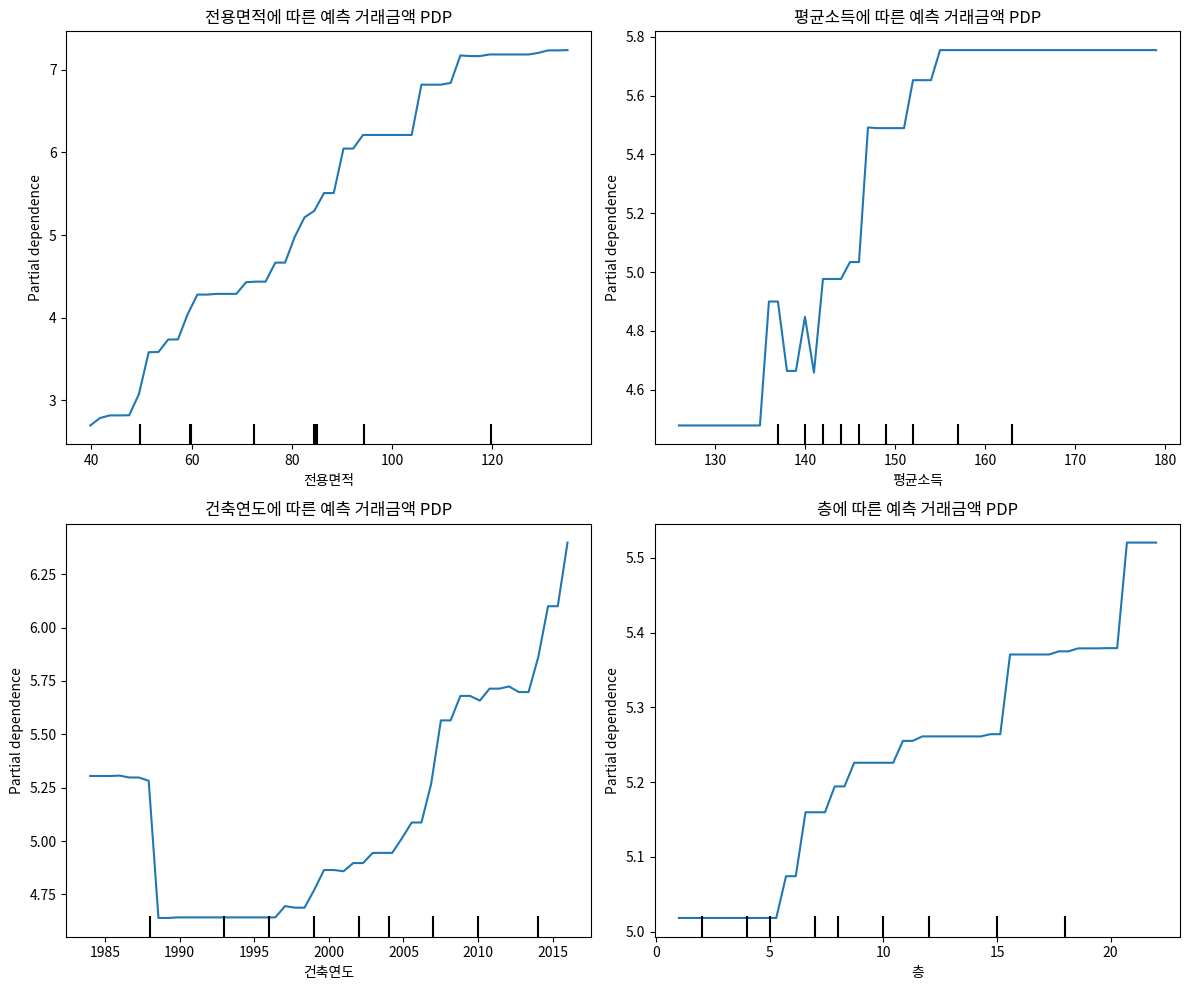

In [ ]:
X_unique = X.drop_duplicates().reset_index(drop=True)

X_unique['층'] = X_unique['층'].astype(int)

num_rows = X_unique.shape[0]

max_samples = 5000000
n_unique = num_rows

if n_unique > max_samples:
    chosen_idx = np.random.choice(n_unique, size=max_samples, replace=False)
    X_sample = X_unique.iloc[chosen_idx].reset_index(drop=True)
else:
    X_sample = X_unique.copy()

# PDP 그리기
from sklearn.inspection import PartialDependenceDisplay
import matplotlib.pyplot as plt
import math

pdp_features = ['전용면적', '평균소득', '건축연도', '층']

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

y_mins = []
y_maxs = []

for i, feat in enumerate(pdp_features):
    display = PartialDependenceDisplay.from_estimator(
        best_pipeline,
        X_sample,
        [feat],
        ax=axes[i],
        grid_resolution=50,
        kind='average'
    )
    axes[i].set_title(f'{feat}에 따른 예측 거래금액 PDP')
    axes[i].set_xlabel(feat)
    axes[i].set_ylabel('예측 거래금액 (억원)')

    ymin, ymax = axes[i].get_ylim()
    y_mins.append(ymin)
    y_maxs.append(ymax)

global_ymin = math.floor(min(y_mins))
global_ymax = math.ceil(max(y_maxs))
yticks = np.arange(global_ymin, global_ymax + 1, 1)

for ax in axes:
    ax.set_ylim(global_ymin, global_ymax)
    ax.set_yticks(yticks)
    ax.set_yticklabels([str(int(y)) for y in yticks])

plt.tight_layout()
plt.show()

Proxy Model

In [32]:
import pandas as pd
from sklearn.tree import DecisionTreeRegressor, export_text


numeric_features = ['전용면적', '건축연도', '층', '연도', '평균소득', '건물연식']

cat_encoder = best_pipeline.named_steps['preprocessor'].named_transformers_['cat']
cats = cat_encoder.categories_[0]  # ['서울특별시 강남구', '서울특별시 서초구', …]
cat_feature_names = [f"지역명_{c}" for c in cats]

final_feature_names = numeric_features + cat_feature_names

# 전처리 전 원본 X_raw 준비
features = ['전용면적','건축연도','층','연도','평균소득','건물연식','지역명']
X_raw = df2[features].reset_index(drop=True)

# LightGBM 모델이 예측할 전체 데이터 예측값 얻기
y_pred_full = best_pipeline.predict(X_raw)

# Proxy Model(Decision Tree) 학습
X_pre = best_pipeline.named_steps['preprocessor'].transform(X_raw)

proxy_model = DecisionTreeRegressor(max_depth=3, random_state=42)
proxy_model.fit(X_pre, y_pred_full)

# Proxy Model 규칙 텍스트로 출력
print("=== Proxy Model (Decision Tree) Rules ===")
tree_rules = export_text(proxy_model, feature_names=final_feature_names)
print(tree_rules)

=== Proxy Model (Decision Tree) Rules ===
|--- 전용면적 <= 90.19
|   |--- 지역명_서울특별시 강남구 <= 0.50
|   |   |--- 전용면적 <= 76.31
|   |   |   |--- value: [3.16]
|   |   |--- 전용면적 >  76.31
|   |   |   |--- value: [4.89]
|   |--- 지역명_서울특별시 강남구 >  0.50
|   |   |--- 전용면적 <= 49.97
|   |   |   |--- value: [6.52]
|   |   |--- 전용면적 >  49.97
|   |   |   |--- value: [11.66]
|--- 전용면적 >  90.19
|   |--- 지역명_서울특별시 강남구 <= 0.50
|   |   |--- 지역명_서울특별시 서초구 <= 0.50
|   |   |   |--- value: [7.05]
|   |   |--- 지역명_서울특별시 서초구 >  0.50
|   |   |   |--- value: [16.88]
|   |--- 지역명_서울특별시 강남구 >  0.50
|   |   |--- 전용면적 <= 144.16
|   |   |   |--- value: [16.61]
|   |   |--- 전용면적 >  144.16
|   |   |   |--- value: [24.39]



LIME

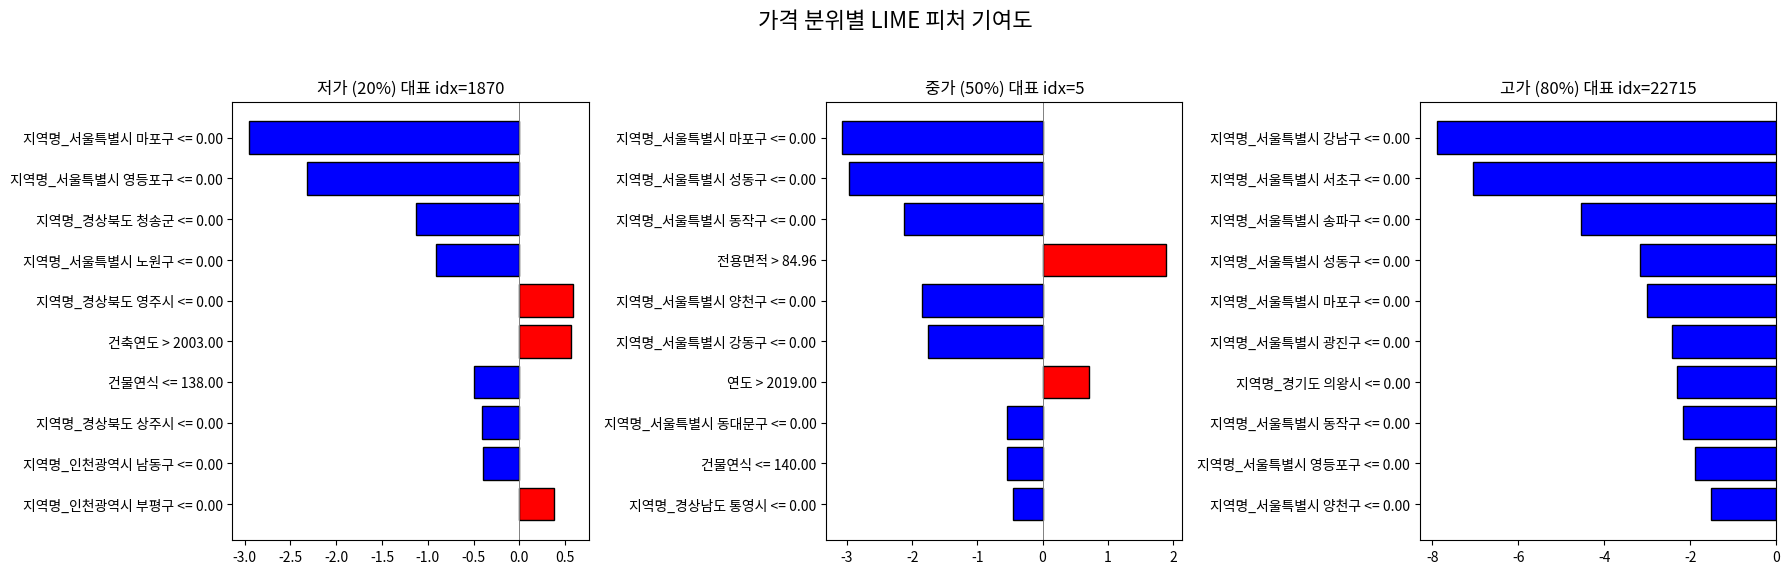

In [ ]:
import numpy as np
import lime.lime_tabular
import matplotlib.pyplot as plt

plt.rc('font', family='Noto Sans CJK JP')
plt.rcParams['axes.unicode_minus'] = False

# 분위값 계산
q_low  = model_df['거래금액'].quantile(0.2)
q_mid  = model_df['거래금액'].quantile(0.5)
q_high = model_df['거래금액'].quantile(0.8)

# 분위별 대표 인덱스
rep_low_idx  = (model_df['거래금액'] - q_low ).abs().idxmin()
rep_mid_idx  = (model_df['거래금액'] - q_mid ).abs().idxmin()
rep_high_idx = (model_df['거래금액'] - q_high).abs().idxmin()

rep_indices = {
    '저가 (20%)':  rep_low_idx,
    '중가 (50%)':  rep_mid_idx,
    '고가 (80%)':  rep_high_idx
}

# 1행 3열 Figure 생성
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
plt.subplots_adjust(wspace=0.4)

n_neighbors  = 2000
num_features = 10
seed         = 42
num_samples  = 5000

for ax, (label, rep_idx) in zip(axes, rep_indices.items()):
    rep_price = model_df.loc[rep_idx, '거래금액']
    
    # 대표 샘플과 거래금액 차이가 가장 작은 순으로 이웃 추출
    distances   = (model_df['거래금액'] - rep_price).abs()
    sorted_idxs = distances.sort_values().index.to_numpy()
    neighbor_idxs = sorted_idxs[:n_neighbors]
    
    X_neighbors = X_pre[neighbor_idxs]   # 이웃 2000개
    X_rep       = X_pre[[rep_idx]]       # 대표 샘플 1개
    
    explainer = lime.lime_tabular.LimeTabularExplainer(
        X_neighbors,
        feature_names=feature_names,
        mode='regression',
        random_state=seed
    )
    predict_fn = lambda x: best_pipeline.named_steps['regressor'].predict(x)
    
    exp = explainer.explain_instance(
        data_row=X_rep[0],
        predict_fn=predict_fn,
        num_features=num_features,
        num_samples=num_samples
    )
    
    feat_weights = exp.as_list()
    feats   = [fw[0] for fw in feat_weights]
    weights = [fw[1] for fw in feat_weights]
    colors  = ['red' if w > 0 else 'blue' for w in weights]
    
    y_pos = np.arange(len(feats))
    ax.barh(y_pos, weights, color=colors, edgecolor='k')
    ax.set_yticks(y_pos)
    ax.set_yticklabels(feats, fontsize=10)
    ax.invert_yaxis()
    ax.set_title(f"{label} 대표 idx={rep_idx}", fontsize=12)
    ax.axvline(0, color='gray', linewidth=0.7)

fig.suptitle("가격 분위별 LIME 피처 기여도", fontsize=16)
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

SHAP

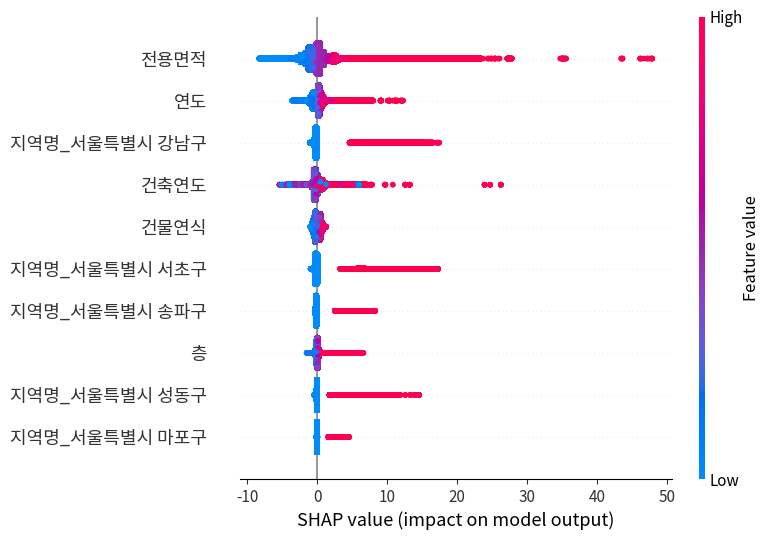

In [ ]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = ""

import shap
import numpy as np
import matplotlib.pyplot as plt

# 데이터 준비
features = ['전용면적','건축연도','층','연도','평균소득','건물연식','지역명']
X_raw = df2[features].reset_index(drop=True)

# 파이프라인으로 전처리 
preprocessor = best_pipeline.named_steps['preprocessor']
X_pre_sparse = preprocessor.transform(X_raw)
try:
    X_pre = X_pre_sparse.toarray()
except AttributeError:
    X_pre = X_pre_sparse  

# NumPy 2D 배열로 변환
X_pre = np.asarray(X_pre)

np.random.seed(42)
n_samples = 5000000
total_rows = X_pre.shape[0]
if total_rows <= n_samples:
    sample_idx = np.arange(total_rows)
else:
    sample_idx = np.random.choice(total_rows, n_samples, replace=False)
X_sample_pre = X_pre[sample_idx]

# 학습된 LightGBM 회귀 모델 꺼내기
lgbm_model = best_pipeline.named_steps['regressor']

# SHAP Explainer 생성 (CPU 모드)
explainer_shap = shap.TreeExplainer(lgbm_model, feature_perturbation="tree_path_dependent")

# 샘플 데이터에 대한 SHAP 값 계산 (2D NumPy 배열로 전달)
shap_values_sample = explainer_shap.shap_values(X_sample_pre)

numeric_features = ['전용면적','건축연도','층','연도','평균소득','건물연식']
cat_encoder = preprocessor.named_transformers_['cat']
cats = cat_encoder.categories_[0]
feature_names = numeric_features + [f"지역명_{c}" for c in cats]

# SHAP Summary Plot (상위 10개 피처만 표시)
shap.summary_plot(
    shap_values_sample,
    X_sample_pre,
    feature_names=feature_names,
    max_display=10
)